# Intelligent E-commerce Search & Ranking

## Project Overview

This project develops an intelligent e-commerce search and ranking system using Natural Language Processing (NLP), information retrieval, semantic embeddings, and machine learning. The objective is to retrieve relevant products based on customer search queries and rank those products according to their relevance.

### Business Problem

E-commerce platforms depend on effective product discovery. Customers may struggle to find relevant products when their search queries use different terminology from product titles or descriptions. Poor search relevance can create friction in the customer journey and potentially reduce engagement and conversion.

### Project Objectives

1. Explore and preprocess an e-commerce product catalog.
2. Develop baseline keyword search using TF-IDF and BM25.
3. Implement semantic search using text embeddings.
4. Improve retrieval efficiency with FAISS.
5. Explore learning-to-rank techniques using LightGBM.
6. Evaluate search quality using Precision@K, Recall@K, and NDCG@K.
7. Translate model performance into actionable product search recommendations.

### Expected Outcome

A working product search pipeline that retrieves and ranks products for customer queries, supported by reproducible evaluation and business-oriented insights.

**Note:** Search relevance metrics will measure retrieval and ranking quality. Conversion or revenue improvements would require additional user behavior data and experimentation.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text processing and search
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rank_bm25 import BM25Okapi

# Notebook display settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


## Understanding Information Retrieval & Search Ranking

A product search engine generally performs two important tasks:

### 1. Retrieval — Finding Candidate Products

The retrieval stage identifies products that may be relevant to a customer's search query.

**Example query:** "wireless headphones for travel"

Traditional retrieval methods such as TF-IDF and BM25 identify products based on keyword matches and term importance. Semantic retrieval methods use embeddings to identify products with similar meanings, even when the exact keywords differ.

### 2. Ranking — Ordering Products by Relevance

Once candidate products are retrieved, a ranking model determines which products should appear first.

Ranking can consider features such as:

- Keyword similarity between query and product.
- Semantic similarity.
- Product category relevance.
- Product attributes.
- Historical engagement signals, when available.

### Search Techniques We'll Explore

| Technique | Purpose | Key Concept |
|---|---|---|
| TF-IDF | Keyword retrieval baseline | Term importance |
| BM25 | Improved keyword-based retrieval | Term frequency and document length |
| Sentence Embeddings | Semantic retrieval | Meaning-based similarity |
| FAISS | Efficient vector search | Approximate or exact nearest-neighbor search |
| LightGBM Ranker | Learning to Rank | Query-product relevance |

### Search Evaluation Metrics

**Precision@K:** Measures how many of the top K retrieved products are relevant.

**Recall@K:** Measures how many relevant products are retrieved within the top K results.

**NDCG@K:** Evaluates ranking quality by rewarding highly relevant products appearing closer to the top.

### Business Relevance

A stronger search system may improve product discovery by placing more relevant items near the top of search results. However, improvements in offline ranking metrics do not automatically establish improvements in customer engagement, conversion, or revenue. These outcomes should be validated through online experimentation.

## 2. Dataset Selection & Understanding

### Dataset: Amazon Products 2023

**Source:** Hugging Face — `aslan-ng/amazon_products_2023`

This dataset contains product listings with descriptive text and category information.

### Relevant Features

| Feature | Description | Search Application |
|---|---|---|
| title | Product name | Keyword matching |
| description | Product description | Semantic understanding |
| main_category | Primary product category | Category analysis and filtering |
| average_rating | Average customer rating | Potential ranking feature |
| rating_number | Number of customer ratings | Potential ranking feature |

### Why This Dataset?

The dataset contains natural-language product information suitable for developing and comparing different search techniques. We will initially use product titles and descriptions as the primary inputs for our search algorithms. Product ratings may eventually be explored as supplementary ranking features, but they are not direct measures of query relevance.

### Important Limitation

The dataset does not provide verified search queries and corresponding relevance judgments. Therefore, we will need a separate evaluation strategy before claiming that one search model outperforms another.

In [2]:
import pyarrow
import pyarrow.dataset
import datasets

print("PyArrow version:", pyarrow.__version__)
print("Datasets version:", datasets.__version__)
print("All imports successful!")


PyArrow version: 26.0.0
Datasets version: 5.1.0
All imports successful!


In [3]:
import sys
import platform
from importlib.metadata import version

print("Python:", sys.version)
print("Executable:", sys.executable)
print("Architecture:", platform.architecture())

for package in ["pyarrow", "numpy", "datasets", "protobuf"]:
    try:
        print(f"{package}: {version(package)}")
    except Exception as error:
        print(f"{package}: {error}")

Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
Executable: C:\Users\GamerTech\anaconda3\python.exe
Architecture: ('64bit', 'WindowsPE')
pyarrow: 26.0.0
numpy: 2.1.3
datasets: 5.1.0
protobuf: 6.33.6


In [4]:
import brotli

# Test whether compression and decompression work
original_text = b"Testing product dataset download"

compressed = brotli.compress(original_text)
decompressed = brotli.decompress(compressed)

print("Brotli test successful:", decompressed == original_text)

Brotli test successful: True


In [5]:
from datasets import load_dataset

dataset = load_dataset(
    "aslan-ng/amazon_products_2023",
    split="train"
)

df = dataset.to_pandas()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (90426, 6)


,title,description,main_category,average_rating,rating_number,product_quality_score
0,"Yamaha Stage Custom Birch 14x5.5 Snare Drum, Cranberry Red",Continuing on the success of the highly acclaimed Yamaha Stage Custom series comes the new Stage Custom Birch (redes...,Musical Instruments,4.8,528.0,4.797543
1,DJ&RPPQ Tablet Kids Case for 10.1 inch (11th Gen 2021) - DJ&RPPQ [Adult & Kids Friendly] Light Weight Anti Slip Shoc...,"Four corner protection\nThe four-corner thickening process can enhance the security of the tablet more effectively, ...",Cell Phones & Accessories,4.6,1685.0,4.599348
2,ProX,"ProX Flight Case DJ Coffin for 10""/12"" Mixer and 2 1200 Style Turntables in Standard Mode with Wheels & Laptop Shelf...",AMAZON FASHION,5.0,2.0,4.500000
3,"Capo for Guitar,Ukulele,Banjo(Zinc Metal,Black)","Color of capo (zinc alloy): BlackMaterial: Zinc Alloy,Silicone rubberSuitable:Acoustic,electric and bass Guitars ,ba...",Musical Instruments,5.0,1.0,4.250000
4,Wrugste Microphone Cable 6.6 feet/2 Meters XLR Male to Female Balanced 3-Pin with Oxygen-Free Copper for Powered Spe...,"【WIDE COMPATIBILITY】: This microphone cable is compatible with devices with 3-pin connectors, such as microphones, s...",Industrial & Scientific,4.9,20.0,4.833333


In [6]:
# Examine the dataset's dimensions and column names
print("DATASET SHAPE")
print(df.shape)

print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Inspect column types and non-null counts
print("\nDATASET INFORMATION")
df.info()

# Identify missing values
print("\nMISSING VALUES")
missing_values = (
    df.isnull()
    .sum()
    .sort_values(ascending = False)
    .to_frame("Missing Count")
)

DATASET SHAPE
(90426, 6)

COLUMN NAMES
['title', 'description', 'main_category', 'average_rating', 'rating_number', 'product_quality_score']

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90426 entries, 0 to 90425
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   title                  90426 non-null  object 
 1   description            90426 non-null  object 
 2   main_category          90426 non-null  object 
 3   average_rating         90426 non-null  float64
 4   rating_number          90426 non-null  float64
 5   product_quality_score  90426 non-null  float64
dtypes: float64(3), object(3)
memory usage: 4.1+ MB

MISSING VALUES


**What we're doing**: Checking which fields exist, identifying missing product information, and looking for potential duplicate listings.

We're checking duplicate titles rather than entire rows because some e-commerce datasets contain lists or nested attributes that cannot be directly compared using `df.duplicated()`.

## 3. Data Quality Assessment

Before building a search engine, we need to evaluate the quality and completeness of the product catalog.

### Key Data Quality Considerations

**1. Missing Product Information**: Products without titles may be difficult to retrieve through keyword-based search. Missing descriptions can also reduce the information available for semantic matching.

**2. Duplicate Product Listings**: Duplicate listings may cause the same or very similar products to appear repeatedly in search results, reducing result diversity.

**3. Product Categories**: Category information helps us understand the composition of the catalog and may eventually support category-specific filtering or ranking.

**4. Customer Ratings**: Ratings and review counts may provide useful product-quality signals. However, they should not replace query relevance when ranking search results.

### Data Preparation Strategy

We will:

- Retain relevant product attributes.
- Remove records without usable product titles.
- Standardize text formatting.
- Handle missing descriptions.
- Create a reproducible development sample.
- Preserve useful product metadata for future ranking experiments.

The objective is to prepare a consistent product catalog while minimizing unnecessary information loss.

In [7]:
# Define the product features we want to retain
desired_columns = ["title", "description", "main_category", "average_rating", "rating_number"]

# Keep only columns available in the dataset
available_columns = [
    col for col in desired_columns
    if col in df.columns
]

print("Available columns:", available_columns)

# Product titles are essential for our search engine
if "title" not in available_columns:
    raise ValueError(
        "The dataset does not contain a 'title' column."
        "Please inspect the column names from Cell 7."
    )

# Create a working copy
product_df = df[available_columns].copy()

# Remove records without titles
product_df = product_df.dropna(subset = ["title"])

# Clean and standardize titles
product_df["title"] = (
    product_df["title"]
    .astype(str)
    .str.strip()
)

# Remove empty titles
product_df = product_df[product_df["title"] != ""].copy()

# Convert descriptions to searchable text
if "description" in product_df.columns:

    def format_description(value):
        if isinstance(value, (list, tuple)):
            return " ".join(str(item) for item in value)

        if value is None:
            return ""

        if isinstance(value, str):
            return value.strip()

        return str(value) if pd.notna(value) else ""

    product_df["description"] = (
        product_df["description"]
        .apply(format_description)
    )

else:
    product_df["description"] = ""

# Remove duplicate title-description combinations
product_df = product_df.drop_duplicates(
    subset=["title", "description"]
)

# Select a reproducible sample of up to 10,000 products
sample_size = min(10000, len(product_df))

product_df = product_df.sample(
    n=sample_size,
    random_state=RANDOM_STATE
).reset_index(drop=True)

# Assign a unique ID for each product in our working catalog
product_df["product_id"] = np.arange(
    1,
    len(product_df) + 1
)

print("WORKING DATASET CREATED")
print("Number of products:", len(product_df))
print("Number of columns:", len(product_df.columns))

display(product_df.head())

Available columns: ['title', 'description', 'main_category', 'average_rating', 'rating_number']
WORKING DATASET CREATED
Number of products: 10000
Number of columns: 6


,title,description,main_category,average_rating,rating_number,product_id
0,Women's Jumpsuit Fake Summer Dress Women Ruffle Layer Tie Boho Off Shoulder Romper Back Ruffle Hem Mini Short Hakama,Womens Solid Jumpsuit Long Sleeve Ruffle Layer Tie Mini Short Romper Jumpsuit\nSize:S Bust:88cm/34.65'' Waist:70...,AMAZON FASHION,5.0,1.0,1
1,"W10295370A water caps replacement Compatible with EDR1RXD1,W10295370,P4RFWB,P8RFWB2L,46-9930,46-9081 (3 Packs)",Is committed to becoming a seller who has better service and quality.\nWare notes\nThe longest period of use is 6 mo...,Amazon Home,5.0,3.0,2
2,"BEYPOVK Car Steering Wheel Cover, Anti-Slip Breathable Carbon Fiber PU Leather Steering Wheel Protector, Universal M...","BEYPOVK Car Steering Wheel Cover, Anti-Slip Breathable Carbon Fiber PU Leather Steering Wheel Protector, Universal M...",Automotive,3.8,23.0,3
3,Grow by Gerber baby-boys 5-pack Short-sleeve Onesies Bodysuits,"This 5-pack of baby boys' onesies bodysuits will make you say ""yippee!"" Made with a soft strentch cotton and spandex...",AMAZON FASHION,4.8,2309.0,4
4,Spenco Women's Slip-on Sneaker Clog,The esplanade will carry you from workday to weekend with blissful casual styling and classic comfort. Twin gore str...,AMAZON FASHION,2.1,6.0,5


**What we're doing**: Creating a manageable, reproducible product catalog. Each product receives a unique identifier, which we'll use later to retrieve and rank search results.

In [8]:
# Examine the distribution of product title lengths
product_df["title_length"] = (
    product_df["title"]
    .str.split()
    .str.len()
)

# Examine the distribution of description lengths
product_df["description_length"] = (
    product_df["description"]
    .str.split()
    .str.len()
)

print("TEXT LENGTH SUMMARY")

display(
    product_df[
        ["title_length", "description_length"]
    ].describe()
)

# Calculate the percentage of products with descriptions
description_coverage = (
    product_df["description"].str.len().gt(0).mean() * 100
)

print(
    f"\nProducts with descriptions: "
    f"{description_coverage:.2f}%"
)

# Examine category distribution, if available
if "main_category" in product_df.columns:

    print("\nTOP 10 PRODUCT CATEGORIES")

    display(
        product_df["main_category"]
        .value_counts()
        .head(10)
        .to_frame("Product Count")
    )

TEXT LENGTH SUMMARY


,title_length,description_length
count,10000.000000,10000.000000
mean,18.340500,104.059800
std,8.712965,89.260631
min,1.000000,1.000000
25%,11.000000,32.000000
50%,18.000000,79.000000
75%,26.000000,157.000000
max,68.000000,1123.000000



Products with descriptions: 100.00%

TOP 10 PRODUCT CATEGORIES


,Product Count
main_category,
AMAZON FASHION,3921
Amazon Home,1528
Tools & Home Improvement,889
Automotive,639
Cell Phones & Accessories,393
Health & Personal Care,392
All Electronics,349
Sports & Outdoors,348
Office Products,338


**What we're doing**: Understanding how much searchable text each product contains and whether certain categories dominate our sample. These findings will help us decide how to combine product titles, descriptions, and categories when building our search engine.

## 4. Exploratory Data Analysis (EDA)

Before developing search and ranking algorithms, we need to understand the structure and characteristics of our product catalog.

### Objectives

Our exploratory analysis focuses on three areas:

**1. Product Category Distribution**: Identify which categories dominate the catalog and understand how category imbalance could affect search coverage and evaluation.

**2. Product Text Characteristics**: Analyze the length of product titles and descriptions to understand how much information is available for keyword matching and semantic retrieval.

**3. Search Data Quality**: Examine text formatting, repeated words, punctuation, and other characteristics that may affect search relevance.

### Business Relevance

E-commerce search quality depends on how effectively the system connects customer intent with relevant products. Understanding the product catalog helps us make informed decisions about text preprocessing, retrieval algorithms, and ranking strategies.

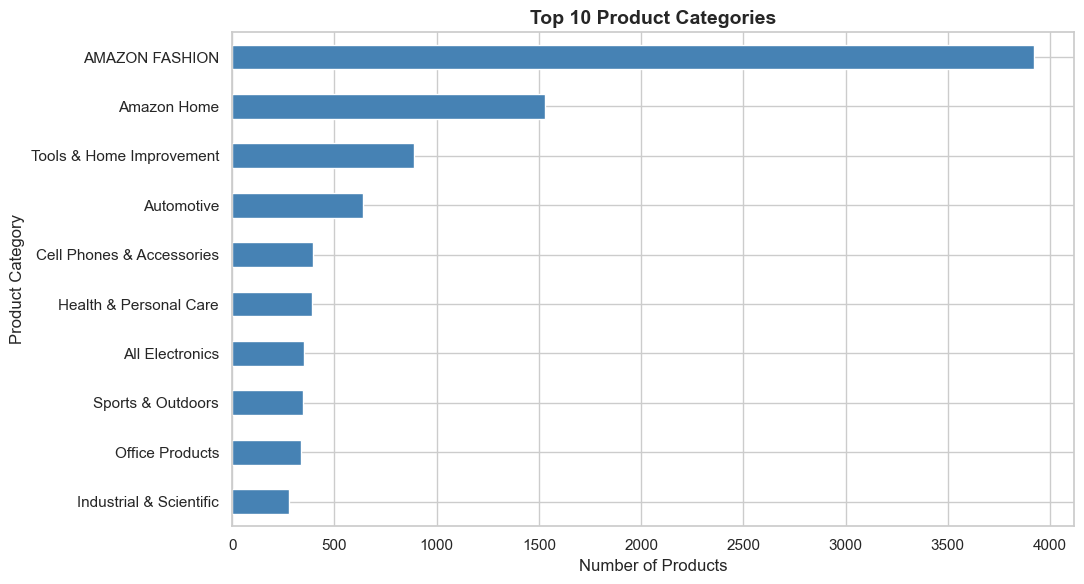

Largest category: AMAZON FASHION
Share of working dataset: 39.21%


In [9]:
# Identify the 10 most common product categories
category_counts = (
    product_df["main_category"]
    .value_counts()
    .head(10)
    .sort_values()
)

# Create a horizontal bar chart
plt.figure(figsize=(11, 6))

category_counts.plot(
    kind="barh",
    color="steelblue"
)

plt.title(
    "Top 10 Product Categories",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Products")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

# Calculate category concentration
top_category = product_df["main_category"].value_counts().index[0]

top_category_share = (
    product_df["main_category"].value_counts().iloc[0]
    / len(product_df)
    * 100
)

print(f"Largest category: {top_category}")
print(f"Share of working dataset: {top_category_share:.2f}%")

**What we're doing**: Visualizing category imbalance and identifying the categories that account for the largest share of products.

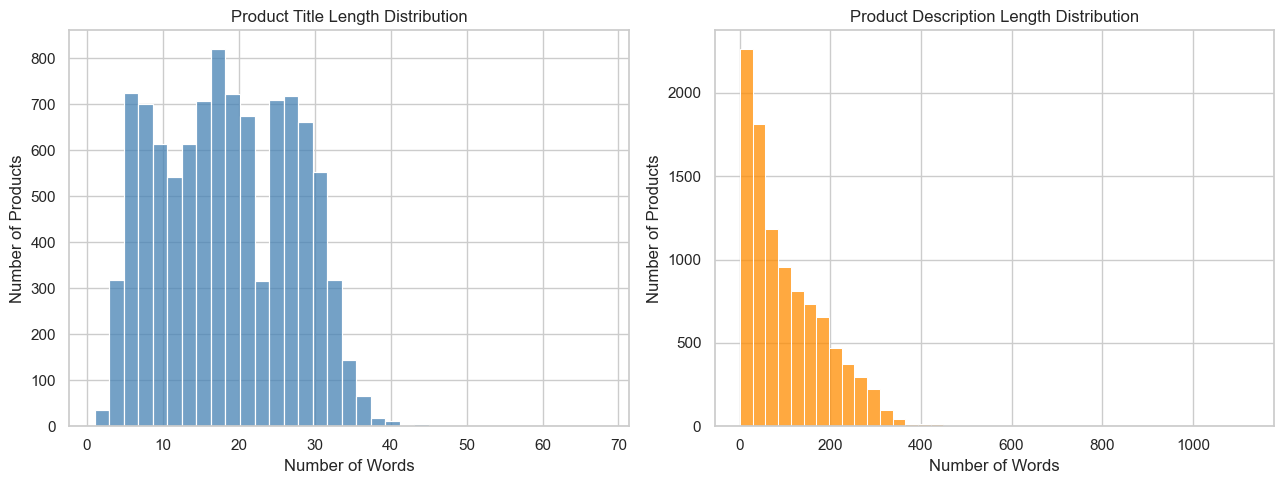

MEDIAN TEXT LENGTHS
Median title length: 18.0
Median description length: 79.0


In [10]:
# Create separate distributions for titles and descriptions
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Product title lengths
sns.histplot(
    product_df["title_length"],
    bins=35,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Product Title Length Distribution")
axes[0].set_xlabel("Number of Words")
axes[0].set_ylabel("Number of Products")

# Product description lengths
sns.histplot(
    product_df["description_length"],
    bins=40,
    ax=axes[1],
    color="darkorange"
)

axes[1].set_title("Product Description Length Distribution")
axes[1].set_xlabel("Number of Words")
axes[1].set_ylabel("Number of Products")

plt.tight_layout()
plt.show()

# Display key summary statistics
print("MEDIAN TEXT LENGTHS")

print(
    "Median title length:",
    product_df["title_length"].median()
)

print(
    "Median description length:",
    product_df["description_length"].median()
)

## 5. Text Preprocessing

Search algorithms require consistent text representations to compare customer queries with product information.

### Preprocessing Strategy

We will apply the following transformations:

**Lowercasing**: Convert text to lowercase so that capitalization differences do not prevent matches.

**Whitespace Normalization**: Remove unnecessary spaces, tabs, and line breaks.

**Punctuation Handling**: Normalize punctuation while preserving useful alphanumeric product information.

**Combining Product Attributes**: Create a searchable text field containing product titles and descriptions.

### Why Combine Titles and Descriptions?

Product titles generally contain the most important identifying information, while descriptions provide additional details about features, specifications, and intended uses. Combining these fields allows the search system to retrieve products based on both direct keyword matches and supporting descriptive information.

### Important Consideration

Aggressive preprocessing can remove meaningful product identifiers, such as model numbers, sizes, or technical specifications. We will therefore begin with relatively conservative text cleaning and retain the original product information for display. This processed text will form the foundation for our TF-IDF and BM25 search baselines.

In [11]:
# Define a reusable text-cleaning function
def clean_text(text):

    # Handle missing or non-string values
    if not isinstance(text, str):
        return ""

    # Convert to lowercase
    text = text.lower()

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    # Remove punctuation except useful characters
    # such as hyphens, periods, and slashes
    text = re.sub(r"[^\w\s\-\./]", " ", text)

    # Remove extra spaces created during cleaning
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Clean titles and descriptions separately
product_df["clean_title"] = (
    product_df["title"].apply(clean_text)
)

product_df["clean_description"] = (
    product_df["description"].apply(clean_text)
)

# Combine the cleaned text into a single searchable field
product_df["search_text"] = (
    product_df["clean_title"]
    + " "
    + product_df["clean_description"]
).str.strip()

# Check the processed text
print("TEXT PREPROCESSING COMPLETE")

display(
    product_df[
        [
            "product_id",
            "title",
            "clean_title",
            "search_text"
        ]
    ].head(3)
)

# Verify that products have searchable text
empty_search_text = (
    product_df["search_text"] == ""
).sum()

print("\nProducts with empty search text:", empty_search_text)

print(
    "Products ready for indexing:",
    len(product_df) - empty_search_text
)

TEXT PREPROCESSING COMPLETE


,product_id,title,clean_title,search_text
0,1,Women's Jumpsuit Fake Summer Dress Women Ruffle Layer Tie Boho Off Shoulder Romper Back Ruffle Hem Mini Short Hakama,women s jumpsuit fake summer dress women ruffle layer tie boho off shoulder romper back ruffle hem mini short hakama,women s jumpsuit fake summer dress women ruffle layer tie boho off shoulder romper back ruffle hem mini short hakama...
1,2,"W10295370A water caps replacement Compatible with EDR1RXD1,W10295370,P4RFWB,P8RFWB2L,46-9930,46-9081 (3 Packs)",w10295370a water caps replacement compatible with edr1rxd1 w10295370 p4rfwb p8rfwb2l 46-9930 46-9081 3 packs,w10295370a water caps replacement compatible with edr1rxd1 w10295370 p4rfwb p8rfwb2l 46-9930 46-9081 3 packs is comm...
2,3,"BEYPOVK Car Steering Wheel Cover, Anti-Slip Breathable Carbon Fiber PU Leather Steering Wheel Protector, Universal M...",beypovk car steering wheel cover anti-slip breathable carbon fiber pu leather steering wheel protector universal mic...,beypovk car steering wheel cover anti-slip breathable carbon fiber pu leather steering wheel protector universal mic...



Products with empty search text: 0
Products ready for indexing: 10000


## 6. Building a Keyword-Based Search Engine

### 6.1 Understanding TF-IDF

TF-IDF (Term Frequency–Inverse Document Frequency) is a statistical technique that measures how important a word is within a document relative to an entire collection of documents. In our project, each product's combined title and description represents a document.

TF-IDF consists of two components:

**1. Term Frequency (TF)**: Measures how frequently a word appears within a product's searchable text. For example, if a customer searches for "wireless headphones," products that mention these words are potentially relevant. However, simply counting words can overemphasize common terms that appear across many products.

**2. Inverse Document Frequency (IDF)**: Measures how uncommon a word is across the product catalog. Words that appear in nearly every product description provide little information for distinguishing products. More specific terms can help identify products that closely match a customer's intent. TF-IDF combines these two concepts to assign greater importance to terms that are frequent within a particular product but relatively uncommon across the catalog.

### 6.2 Understanding Cosine Similarity

Once products and search queries are converted into TF-IDF vectors, we need a method to compare them. Cosine similarity measures the similarity between two vectors based on the angle between them.

Its formula is:

**Cosine Similarity = (A · B) / (||A|| × ||B||)**

Where:

- **A** represents the customer's query vector.
- **B** represents a product's TF-IDF vector.
- **A · B** is the dot product between the vectors.
- **||A|| and ||B||** represent their magnitudes.

With the nonnegative TF-IDF vectors used here, similarity scores range from 0 to 1. A score closer to 1 indicates greater similarity between the query and product text. A score of 0 indicates that the vectors share no weighted terms.

### 6.3 Why Are We Using These Techniques?

TF-IDF and cosine similarity provide a relatively simple, interpretable baseline for product search. They allow us to:

- Retrieve products based on matching keywords.
- Rank products by textual relevance.
- Establish a benchmark for evaluating more advanced search techniques.
- Identify limitations of keyword matching, such as difficulty understanding synonyms and customer intent.

### Business Relevance

Relevant search results can make it easier for customers to discover products that meet their needs. However, TF-IDF only measures textual similarity. It does not directly measure customer satisfaction, purchase likelihood, or conversion. We will evaluate search relevance separately before making any claims about business impact.

In [12]:
# Initialize the TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features = 20000,
    stop_words = "english",
    ngram_range = (1, 2),
    min_df = 2, 
    max_df = 0.95
)

# Convert product text into TF-IDF vectors
tfidf_matrix = tfidf_vectorizer.fit_transform(
    product_df["search_text"]
)

# Display information about TF-IDF index
print("TF-IDF INDEX CREATED")

print("Number of indexed products:", tfidf_matrix.shape[0])

print("Number of vocabulary features:", tfidf_matrix.shape[1])

print("Matrix type:", type(tfidf_matrix))

print("Non-zero values:", tfidf_matrix.nnz)

# Calculate matrix sparsity
total_elements = (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])

sparsity = (1 - tfidf_matrix.nnz / total_elements) * 100

print(f"Matrix sparsity: {sparsity:.2f}%")

TF-IDF INDEX CREATED
Number of indexed products: 10000
Number of vocabulary features: 20000
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Non-zero values: 685424
Matrix sparsity: 99.66%


**What this code does**: It converts each product's searchable text into a numerical vector. The resulting matrix contains one row per product and one column per vocabulary feature. We've configured the vectorizer to consider individual words and two-word phrases, exclude common English stop words, and limit the vocabulary to 20,000 features.

### 6.4 Creating the Product Search Index

The TF-IDF vectorizer transforms our product catalog into a numerical matrix that can be used for search and retrieval. Each row represents a product, while each column represents a word or two-word phrase learned from the catalog.

### Understanding Our Vectorizer Configuration

**Maximum Features: 20,000**

Limits the vocabulary to a maximum of 20,000 features, helping control memory usage and computational complexity.

**English Stop Words**

Removes common English words that typically provide limited value for distinguishing products.

**N-Gram Range: (1, 2)**

Includes both individual words (unigrams) and consecutive two-word phrases (bigrams). For example, the product phrase "wireless gaming mouse" can generate features such as "wireless," "gaming," "mouse," "wireless gaming," and "gaming mouse." Bigrams help preserve some context that would otherwise be lost when treating every word independently.

**Minimum Document Frequency: 2**

Excludes terms appearing in fewer than two products. This reduces extremely rare vocabulary features, although it may also remove useful model numbers or unique product identifiers.

**Maximum Document Frequency: 0.95**

Excludes terms appearing in more than 95% of products because they provide little distinction across the catalog.

### Understanding Matrix Sparsity

The TF-IDF matrix is sparse because most products contain only a small fraction of all possible vocabulary terms. For example, a product describing a steering wheel cover will generally have zero values for features associated with baby clothing or headphones. Sparse matrices store only nonzero values, making it practical to represent thousands of products without allocating memory for every possible product-feature combination.

### Why This Matters for Search

The index gives us a consistent numerical representation of the entire catalog. When a customer enters a query, we can transform it using the same vocabulary and compare it against the indexed products. This enables us to retrieve and rank products without manually defining matching rules for every possible search term.

In [13]:
def search_products_tfidf(query, top_k=10):
    """
    Retrieve products ranked by TF-IDF cosine similarity.

    Parameters
    ----------
    query : str
        Customer's search query.

    top_k : int
        Maximum number of products to return.

    Returns
    -------
    pd.DataFrame
        Top-ranked products with similarity scores.
    """

    # Validate the query
    cleaned_query = clean_text(query)

    if not cleaned_query:
        print("Please enter a valid search query.")
        return pd.DataFrame()

    # Convert the customer query into a TF-IDF vector
    query_vector = tfidf_vectorizer.transform(
        [cleaned_query]
    )

    # Compare the query against every indexed product
    similarity_scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    ).flatten()

    # Rank products from highest to lowest similarity
    ranked_indices = np.argsort(
        similarity_scores
    )[::-1]

    # Exclude products with zero similarity
    ranked_indices = [
        idx for idx in ranked_indices
        if similarity_scores[idx] > 0
    ][:top_k]

    # Retrieve product information
    results = product_df.iloc[
        ranked_indices
    ][
        [
            "product_id",
            "title",
            "main_category",
            "average_rating",
            "rating_number"
        ]
    ].copy()

    # Add similarity scores
    results["similarity_score"] = (
        similarity_scores[ranked_indices]
    )

    # Reset the index for easier reading
    results = results.reset_index(drop=True)

    # Start result ranking at 1
    results.index = results.index + 1
    results.index.name = "Rank"

    return results


print("TF-IDF search function created successfully!")

TF-IDF search function created successfully!


**What this code does**: It creates a reusable search function that accepts a customer query, calculates its similarity against the product catalog, and returns the highest-ranked matching products.

In [14]:
# Define example customer search queries
test_queries = [
    "wireless headphones",
    "women summer dress",
    "car steering wheel cover",
    "baby cotton bodysuit"
]

# Retrieve the five highest-ranked products for each query
for query in test_queries:

    print("\n" + "=" * 70)
    print(f"SEARCH QUERY: {query}")
    print("=" * 70)

    results = search_products_tfidf(
        query = query,
        top_k = 5
    )

    display(results)


SEARCH QUERY: wireless headphones


,product_id,title,main_category,average_rating,rating_number,similarity_score
Rank,,,,,,
1,2316,"JBL Vibe Buds True Wireless Headphones - Black, Small",All Electronics,4.4,89.0,0.557803
2,8537,Fulext Sleep-Headphones-Headband-Bluetooth - Headphones for Sleeping Sleep Mask Headphones with Thin HD Stereo Speak...,All Electronics,4.4,493.0,0.324237
3,8804,"Cosyband Sleep Headphones Wireless Headband, Sports Wireless Earphones Music Sleeping Headphones Mask Earbuds with H...",All Electronics,3.8,9.0,0.317562
4,270,"PHILIPS GO A7507 Wireless Sports Headphones with Noise Canceling Pro (ANC), Bluetooth Multipoint and Bone Conduction...",All Electronics,3.9,9.0,0.300607
5,7743,"WHITOR Waterproof Wireless Headphones,5.0 Bluetooth Wireless Earplugs with Touch Control,Running Stereo e-Sports Gam...",All Electronics,3.1,2.0,0.288159



SEARCH QUERY: women summer dress


,product_id,title,main_category,average_rating,rating_number,similarity_score
Rank,,,,,,
1,4146,Summer Womens One Shouder Mini Dress Cutout Waist Beach Party Short Dress,AMAZON FASHION,3.4,3.0,0.429394
2,3102,Women Dresses Summer Pleated Mini Boho Dress Cute Sleeveless Flowy Beach Straight Tee Dress Round Neck Dress,AMAZON FASHION,3.0,1.0,0.398713
3,3471,Hotouch Black Dress Summer Dress V Neck Babydoll Dress for Women 2023 Womens Dresses Puff Sleeve Casual Dresses,AMAZON FASHION,2.9,8.0,0.322827
4,2975,Dresses That Hide Belly Fat Beach Dresses for Women Summer Scoop Neck Cotton Casual T Shirt Sleeveless Loose,AMAZON FASHION,2.0,1.0,0.305414
5,94,Women's Summer Dresses 2023 Casual Sleeveless Mini Dress Dressy Casual Loose Short Flowy Pleated Sundress,AMAZON FASHION,5.0,1.0,0.298012



SEARCH QUERY: car steering wheel cover


,product_id,title,main_category,average_rating,rating_number,similarity_score
Rank,,,,,,
1,6560,"Lovely Tree Frogs Steering Wheel Cover for Women Men, Universal 15 Inch Anti Slip and Sweat Absorption Auto Car Wrap...",Automotive,5.0,1.0,0.731653
2,1472,"Rose Gold Faux Glitter Print Steering Wheel Cover for Women Men, Universal 15 Inch Anti Slip and Sweat Absorption Au...",Automotive,2.7,4.0,0.731369
3,463,"red White Polka dot Steering Wheel Cover for Women Men, Universal 15 Inch Anti Slip and Sweat Absorption Auto Car Wr...",Automotive,4.7,4.0,0.730646
4,8780,"Bling Leather Steering Wheel Cover,15 Inch Soft Leather Car Wheel Cover with Colorful Crystal Diamond,Universal Non-...",Automotive,3.5,53.0,0.699898
5,3182,"LoyaForba Car Steering Wheel Cover, Universal 14.5-15 Inch, Soft Anti-Slip Neoprene Protector for Steering Wheel, Br...",Automotive,3.7,75.0,0.695348



SEARCH QUERY: baby cotton bodysuit


,product_id,title,main_category,average_rating,rating_number,similarity_score
Rank,,,,,,
1,4722,Metallica unisex-baby Baby Boys' Little Horseman Bodysuit,AMAZON FASHION,3.9,12.0,0.444783
2,6551,"Gerber Baby Boys 3-piece Onesies Bodysuit, Footed Pant, and Cap Set",AMAZON FASHION,4.3,119.0,0.415991
3,7895,"Viworld Newborn Baby Girl Romper, Infant Baby Girls Ruffle Sleeve Bodysuit Casual Toddler Coming Home Summer Jumpsui...",AMAZON FASHION,4.3,31.0,0.347166
4,4286,Creative Knitwear Infant Bodysuit - Striped and Solid - College Baby Miami Gameday Gear,AMAZON FASHION,5.0,2.0,0.339392
5,1112,Gerber Baby Boys' 2-Pack Long Sleeve Henley Onesies,AMAZON FASHION,4.8,21.0,0.318944


**What to look for in the results**:

For each search query, examine whether the highest-ranked products genuinely match the customer's intended purchase. For example, when searching for "wireless headphones", we want to know whether the results contain actual wireless headphones rather than unrelated products that happen to mention the words "wireless" or "headphones."

Also examine the similarity scores. These are measures of textual similarity, not probabilities of purchase or relevance. A high score does not automatically mean a product is useful to the customer.

### 6.5 TF-IDF Search Results & Initial Evaluation

We tested our TF-IDF search engine using two customer queries: **"women summer dress"** and **"wireless headphones."** The objective was to assess whether the search engine could retrieve products that matched the customer's intended product category and whether the ranking appeared reasonable.

#### Query 1: Women Summer Dress

The five highest-ranked products were all summer dresses within the AMAZON FASHION category. The highest-ranked product, "Summer Womens One Shouder Mini Dress Cutout Waist Beach Party Short Dress," received a cosine similarity score of approximately **0.4294**. The remaining four products received scores ranging from approximately **0.2980 to 0.3987**.

**Interpretation**
- All five products appear relevant to the customer's broad search intent.
- The search engine successfully retrieved products containing closely related terms such as "women," "summer," and "dress."
- Some results contain repetitive keywords, suggesting that keyword-heavy titles may influence rankings.
- Product ratings varied substantially, from 2.0 to 5.0 stars, demonstrating that textual relevance and customer ratings are different signals.

#### Query 2: Wireless Headphones

The highest-ranked product was "JBL Vibe Buds True Wireless Headphones," with a similarity score of approximately **0.5578**. The remaining results included sleep headphones, wireless headbands, sports headphones, and Bluetooth headphones, with similarity scores ranging from approximately **0.2882 to 0.3242**.

**Interpretation**

- All five products appear broadly relevant to wireless audio products.
- The JBL product received a noticeably higher similarity score than the remaining results.
- The search engine retrieved different types of headphones, demonstrating reasonable coverage of the broad query.
- However, some results emphasize specialized use cases, such as sleeping or sports, which may not match every customer's intended product type.

#### Key Findings

**1. TF-IDF provides a useful keyword-search baseline.** Both queries returned products that were broadly consistent with customer intent.

**2. Similarity scores are not probabilities of relevance.** A score of 0.56 does not mean a product has a 56% probability of being relevant. It measures similarity between the query and product text.

**3. Textual relevance does not capture every aspect of product quality.** The current model does not directly consider ratings, review volume, product availability, price, or historical customer interactions.

**4. Keyword matching has limitations.** TF-IDF may struggle with synonyms, ambiguous queries, and products that describe the same concept using different terminology.

### Evaluation Limitation

These observations are based on manual inspection of two queries, not a formal relevance evaluation. To compare retrieval algorithms objectively, we will eventually need a set of search queries with independently assigned product relevance labels.

### Business Implications

The initial results suggest that TF-IDF can provide a functional baseline for product discovery. However, improving a search engine requires more than matching keywords. We must also consider ranking quality, query intent, and how effectively relevant products appear near the top of search results. This motivates our next experiment: **BM25**, a ranking algorithm specifically designed for information retrieval.

## 7. Building a BM25 Search Engine

### 7.1 What Is BM25?

BM25 (Best Matching 25) is a probabilistic information-retrieval ranking function commonly used to score documents based on their relevance to a search query. Like TF-IDF, BM25 uses keyword matching and the relative rarity of words across the document collection. However, BM25 introduces two important improvements:

**1. Term Frequency Saturation**

In traditional keyword matching, repeating a search term many times can disproportionately increase a document's score. BM25 reduces this effect by applying diminishing returns to repeated term occurrences. For example, a product mentioning "headphones" 20 times should not automatically outrank a more relevant product mentioning it five times.

**2. Document Length Normalization**

Longer product descriptions naturally contain more words and therefore have more opportunities to match search terms. BM25 adjusts for document length so that longer descriptions do not automatically receive an advantage simply because they contain more text.

### 7.2 How BM25 Works

BM25 calculates a relevance score using:
- **Term frequency:** How often a query term appears in a product.
- **Inverse document frequency:** How rare the term is across the catalog.
- **Document length:** How long the product text is relative to the average document.
- **Tuning parameters:** Controls for term frequency saturation and length normalization.

Two important parameters are:

**k1 = 1.5**: Controls how quickly additional occurrences of a term stop contributing significantly to the relevance score.

**b = 0.75**: Controls how strongly document length affects the score.

A value of 0 means no length normalization, while a value of 1 applies full length normalization. These are reasonable starting values, but they are not necessarily optimal for our product catalog.

### 7.3 Why Compare BM25 Against TF-IDF?

Our product descriptions average approximately 104 words, compared with 18 words for titles. Because product text varies in length, BM25's document length normalization may influence how products are ranked. By comparing both algorithms, we can investigate whether BM25 produces more useful search results, particularly for queries where relevant keywords appear in longer descriptions.

### Business Relevance

Better search ranking can help customers locate relevant products more efficiently. However, we cannot assume BM25 improves customer experience or conversion without evaluating its search results. Our objective is to compare the algorithms systematically and identify their respective strengths and limitations.

In [15]:
# Tokenize each product's searchable text
# BM25 requires a list of words for each product
tokenized_corpus = [
    text.split()
    for text in product_df["search_text"]
]

# Initialize the BM25 ranking model
bm25_model = BM25Okapi(
    tokenized_corpus,
    k1=1.5,
    b=0.75
)

# Inspect the index
print("BM25 INDEX CREATED")

print("Number of indexed products:", len(tokenized_corpus))

print(
    "Average document length:",
    round(bm25_model.avgdl, 2)
)

print("BM25 k1 parameter:", bm25_model.k1)
print("BM25 b parameter:", bm25_model.b)

# Preview tokenized product text
print("\nSAMPLE TOKENIZED PRODUCT")

print(tokenized_corpus[0][:30])

BM25 INDEX CREATED
Number of indexed products: 10000
Average document length: 123.77
BM25 k1 parameter: 1.5
BM25 b parameter: 0.75

SAMPLE TOKENIZED PRODUCT
['women', 's', 'jumpsuit', 'fake', 'summer', 'dress', 'women', 'ruffle', 'layer', 'tie', 'boho', 'off', 'shoulder', 'romper', 'back', 'ruffle', 'hem', 'mini', 'short', 'hakama', 'womens', 'solid', 'jumpsuit', 'long', 'sleeve', 'ruffle', 'layer', 'tie', 'mini', 'short']


**What this code does**: It splits every product's searchable text into individual terms and builds a BM25 index over the 10,000-product catalog.
Unlike TF-IDF, which creates a sparse numerical feature matrix, this BM25 implementation uses tokenized documents and term statistics to calculate query-dependent relevance scores.

In [16]:
def search_products_bm25(query, top_k=10):
    """
    Retrieve products ranked by BM25 relevance scores.

    Parameters
    ----------
    query : str
        Customer's search query.

    top_k : int
        Maximum number of products to return.

    Returns
    -------
    pd.DataFrame
        Top-ranked products with BM25 scores.
    """

    # Validate and preprocess the query
    cleaned_query = clean_text(query)

    if not cleaned_query:
        print("Please enter a valid search query.")
        return pd.DataFrame()

    # Tokenize the search query
    query_tokens = cleaned_query.split()

    # Calculate BM25 scores for all indexed products
    bm25_scores = bm25_model.get_scores(
        query_tokens
    )

    # Rank products from highest to lowest BM25 score
    ranked_indices = np.argsort(
        bm25_scores
    )[::-1]

    # Keep products with positive scores
    ranked_indices = [
        idx for idx in ranked_indices
        if bm25_scores[idx] > 0
    ][:top_k]

    # Retrieve product information
    results = product_df.iloc[
        ranked_indices
    ][
        [
            "product_id",
            "title",
            "main_category",
            "average_rating",
            "rating_number"
        ]
    ].copy()

    # Add BM25 scores
    results["bm25_score"] = (
        bm25_scores[ranked_indices]
    )

    # Reset ranking index
    results = results.reset_index(drop=True)

    results.index = results.index + 1
    results.index.name = "Rank"

    return results


print("BM25 search function created successfully!")

BM25 search function created successfully!


**What this code does**: It creates a reusable function that accepts a customer search query, calculates BM25 relevance scores, and returns the highest-ranked matching products. Note that BM25 scores and TF-IDF cosine similarity scores are on different scales. We should compare the quality and ordering of results rather than directly comparing their numerical values.

In [17]:
# Use the same queries to compare both search algorithms
comparison_queries = [
    "wireless headphones",
    "women summer dress",
    "car steering wheel cover",
    "baby cotton bodysuit"
]

for query in comparison_queries:

    print("\n" + "=" * 75)
    print(f"SEARCH QUERY: {query}")
    print("=" * 75)

    # Retrieve the top five products using TF-IDF
    tfidf_results = search_products_tfidf(
        query,
        top_k=5
    )

    # Retrieve the top five products using BM25
    bm25_results = search_products_bm25(
        query,
        top_k=5
    )

    print("\nTF-IDF RESULTS")
    display(tfidf_results)

    print("\nBM25 RESULTS")
    display(bm25_results)

    # Calculate overlap between the top-five result sets
    tfidf_ids = set(tfidf_results["product_id"])
    bm25_ids = set(bm25_results["product_id"])

    overlap = len(tfidf_ids.intersection(bm25_ids))

    print(
        f"\nTop-5 product overlap: {overlap}/5"
    )


SEARCH QUERY: wireless headphones

TF-IDF RESULTS


,product_id,title,main_category,average_rating,rating_number,similarity_score
Rank,,,,,,
1,2316,"JBL Vibe Buds True Wireless Headphones - Black, Small",All Electronics,4.4,89.0,0.557803
2,8537,Fulext Sleep-Headphones-Headband-Bluetooth - Headphones for Sleeping Sleep Mask Headphones with Thin HD Stereo Speak...,All Electronics,4.4,493.0,0.324237
3,8804,"Cosyband Sleep Headphones Wireless Headband, Sports Wireless Earphones Music Sleeping Headphones Mask Earbuds with H...",All Electronics,3.8,9.0,0.317562
4,270,"PHILIPS GO A7507 Wireless Sports Headphones with Noise Canceling Pro (ANC), Bluetooth Multipoint and Bone Conduction...",All Electronics,3.9,9.0,0.300607
5,7743,"WHITOR Waterproof Wireless Headphones,5.0 Bluetooth Wireless Earplugs with Touch Control,Running Stereo e-Sports Gam...",All Electronics,3.1,2.0,0.288159



BM25 RESULTS


,product_id,title,main_category,average_rating,rating_number,bm25_score
Rank,,,,,,
1,6986,"AHOKEGE Open Ear Clip-on Earbuds Wireless Bluetooth Headphones for Android iPhone, Earbud & in-Ear Headphones, Bluet...",All Electronics,3.8,61.0,17.804874
2,8804,"Cosyband Sleep Headphones Wireless Headband, Sports Wireless Earphones Music Sleeping Headphones Mask Earbuds with H...",All Electronics,3.8,9.0,17.445234
3,2316,"JBL Vibe Buds True Wireless Headphones - Black, Small",All Electronics,4.4,89.0,16.778958
4,3283,"YICFIS Single Open Ear Headphones Wireless Bluetooth with 16mm Large Drivers for Powerful Sound, 8H Playtime Bluetoo...",All Electronics,4.1,28.0,15.881448
5,886,"Jesebang Wireless Earbud, Bluetooth Headphones 5.3 Stereo Earphones 2023 Ear Buds 30H ENC Mic, in-Ear Earbud USB-C L...",All Electronics,4.8,174.0,15.759650



Top-5 product overlap: 2/5

SEARCH QUERY: women summer dress

TF-IDF RESULTS


...


Top-5 product overlap: 4/5

SEARCH QUERY: baby cotton bodysuit

TF-IDF RESULTS


,product_id,title,main_category,average_rating,rating_number,similarity_score
Rank,,,,,,
1,4722,Metallica unisex-baby Baby Boys' Little Horseman Bodysuit,AMAZON FASHION,3.9,12.0,0.444783
2,6551,"Gerber Baby Boys 3-piece Onesies Bodysuit, Footed Pant, and Cap Set",AMAZON FASHION,4.3,119.0,0.415991
3,7895,"Viworld Newborn Baby Girl Romper, Infant Baby Girls Ruffle Sleeve Bodysuit Casual Toddler Coming Home Summer Jumpsui...",AMAZON FASHION,4.3,31.0,0.347166
4,4286,Creative Knitwear Infant Bodysuit - Striped and Solid - College Baby Miami Gameday Gear,AMAZON FASHION,5.0,2.0,0.339392
5,1112,Gerber Baby Boys' 2-Pack Long Sleeve Henley Onesies,AMAZON FASHION,4.8,21.0,0.318944



BM25 RESULTS


,product_id,title,main_category,average_rating,rating_number,bm25_score
Rank,,,,,,
1,6551,"Gerber Baby Boys 3-piece Onesies Bodysuit, Footed Pant, and Cap Set",AMAZON FASHION,4.3,119.0,21.621554
2,7895,"Viworld Newborn Baby Girl Romper, Infant Baby Girls Ruffle Sleeve Bodysuit Casual Toddler Coming Home Summer Jumpsui...",AMAZON FASHION,4.3,31.0,19.400951
3,2212,Gerber Baby 15 Piece Onesies Bodysuit Multi Pack,AMAZON FASHION,4.5,34.0,18.474420
4,4722,Metallica unisex-baby Baby Boys' Little Horseman Bodysuit,AMAZON FASHION,3.9,12.0,16.181275
5,4286,Creative Knitwear Infant Bodysuit - Striped and Solid - College Baby Miami Gameday Gear,AMAZON FASHION,5.0,2.0,14.826849



Top-5 product overlap: 4/5


**What we're examining**:

We're comparing whether TF-IDF and BM25 retrieve the same products and whether they rank those products differently. The top-five overlap tells us how many products appear in both result sets, regardless of their positions. For example, an overlap of 3/5 means three products appear in both algorithms' top-five results. It does not tell us which algorithm is better.

We'll need relevance judgments to determine whether one algorithm consistently places more relevant products higher.

### 7.4 Comparing TF-IDF and BM25 Search Results

We evaluated TF-IDF and BM25 using four customer search queries across our 10,000-product catalog.

The objective was to understand how the algorithms differ in product retrieval, ranking order, and their ability to capture customer search intent.

#### Comparison Results

| Search Query | Top-5 Overlap | Key Observation |
|---|---|---|
| Wireless headphones | 2/5 | Different wireless audio products were prioritized. |
| Women summer dress | 3/5 | BM25 retrieved a swimsuit among otherwise relevant dresses. |
| Car steering wheel cover | 4/5 | Both algorithms retrieved largely the same products. |
| Baby cotton bodysuit | 4/5 | Strong agreement on product selection, with differences in ranking order. |

#### Finding 1: Retrieval Algorithms Produce Different Rankings

For the query "wireless headphones," TF-IDF ranked JBL Vibe Buds first, while BM25 ranked AHOKEGE open-ear earbuds first. Only two products appeared in both algorithms' top-five results. This demonstrates how differences in term weighting, document length normalization, and tokenization can affect which products are prioritized.

#### Finding 2: Keyword Relevance Does Not Guarantee Intent Matching

For the query "women summer dress," TF-IDF returned five dress listings. BM25 returned four dress listings and one two-piece swimsuit listing.

Although the swimsuit listing contains related terms such as "women" and "summer," it appears less relevant to a customer specifically searching for a dress. This illustrates an important limitation of keyword-based retrieval: matching related words does not necessarily mean understanding the customer's intended product.

#### Finding 3: Agreement Varies by Search Query

Both algorithms returned four of the same five products for "car steering wheel cover" and "baby cotton bodysuit." This suggests that some queries produce relatively consistent retrieval results, while others are more sensitive to the choice of ranking algorithm.

#### Finding 4: Product Quality and Textual Relevance Are Different

The current search models rank products using text-based relevance signals.

They do not directly consider customer ratings, review volume, pricing, inventory availability, or historical purchasing behavior. As a result, a product can rank highly because its text matches the query, even when its customer rating is relatively low. These additional signals could eventually be considered in a separate ranking stage, provided they are appropriately validated.

### Evaluation Limitations

Our comparison is currently qualitative and based on four example queries.

Top-five overlap measures agreement between algorithms, not ranking quality. Furthermore, TF-IDF and BM25 use different tokenization approaches in our current implementation, so their differences cannot be attributed entirely to their ranking formulas.

We therefore cannot conclude that either algorithm consistently outperforms the other. A more rigorous evaluation will require independently labeled query-product relevance judgments and ranking metrics such as Precision@K and NDCG@K.

### Business Implications

These results highlight why e-commerce search requires more than basic keyword matching. A useful search engine must retrieve products that satisfy customer intent, prioritize relevant results, and eventually incorporate additional signals that support product discovery.

Our next step is to explore semantic search, which represents product information using contextual embeddings rather than relying exclusively on exact keyword matches.

## 8. Building a Semantic Search Engine

### 8.1 What Is Semantic Search?

Semantic search is an information-retrieval approach that attempts to identify relevant products based on the meaning of a customer's query, rather than relying exclusively on exact keyword matches.

Our existing TF-IDF and BM25 search engines calculate relevance using the words appearing in product titles and descriptions.

These techniques work well when customers use terminology similar to the product listings. However, they can struggle when customers describe a product differently from how the seller describes it.

### Example: Understanding Customer Intent

Consider a customer searching for:

**"Comfortable shoes for standing all day"**

A keyword-based search engine may prioritize products that explicitly contain words such as "comfortable," "standing," and "shoes."

However, relevant products might instead be described as:

- Cushioned walking sneakers
- Supportive work footwear
- Ergonomic slip-resistant shoes

These listings may satisfy the customer's needs even without matching every query term. Semantic search attempts to capture these relationships through numerical representations called embeddings.

### 8.2 What Are Sentence Embeddings?

Sentence embeddings are dense numerical vectors generated by language models trained to represent relationships between text passages.

For example, the phrases:

**"Wireless earbuds for running"**

and

**"Bluetooth sports earphones"**

have different wording but related meanings.

A suitable embedding model may represent these phrases as vectors that are relatively close together. Unlike TF-IDF, where individual dimensions correspond to specific words or phrases, embedding dimensions represent learned features of the text.

### 8.3 How Our Semantic Search System Will Work

Our semantic search pipeline consists of five steps:

1. Combine product titles and descriptions into searchable text.
2. Generate an embedding for every product using a pretrained Sentence Transformer.
3. Convert a customer's search query into an embedding using the same model.
4. Compare the query embedding with product embeddings using cosine similarity.
5. Return the highest-ranked products.

### 8.4 Why Use a Pretrained Model?

Training a language model from scratch would require substantial data, computing resources, and time.

Instead, we'll use a pretrained Sentence Transformer that already captures useful linguistic relationships.

This allows us to focus on building and evaluating the search system rather than training a foundational language model.

### Business Relevance

Semantic search could improve product discovery when customers use conversational queries, synonyms, or descriptions of their needs instead of exact product names. However, semantic similarity does not guarantee product relevance.

For example, a model might recognize that dresses and swimsuits are related to summer fashion without understanding that a customer specifically wants a dress. We'll therefore compare semantic search against our keyword-based baselines rather than assuming it will perform better.

In [18]:
# Import the pretrained embedding model
from sentence_transformers import SentenceTransformer

# Import utilities for numerical operations
import numpy as np

# Load a lightweight pretrained Sentence Transformer
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device="cpu"
)

print("Sentence Transformer loaded successfully!")
print("Embedding dimensions:", embedding_model.get_sentence_embedding_dimension())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Sentence Transformer loaded successfully!
Embedding dimensions: 384


C:\Users\GamerTech\AppData\Local\Temp\ipykernel_12256\1800368161.py:14: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimensions:", embedding_model.get_sentence_embedding_dimension())


### 8.5 Selecting Our Sentence Transformer Model

For this project, we're using the pretrained model **all-MiniLM-L6-v2**. This model is designed to convert sentences and short passages into numerical embeddings that can be compared using similarity measures.

### Why This Model?

**1. Lightweight Architecture**: The model is relatively small compared with many modern language models, making it practical to run locally without requiring a dedicated GPU.

**2. Fixed-Length Embeddings**: Each product is represented by a 384-dimensional vector. This gives us a consistent representation for comparing customer queries against product listings.

**3. General-Purpose Semantic Representations**: The model has been trained to capture relationships between different text passages. It provides a useful starting point for evaluating semantic retrieval without requiring task-specific training.

### How This Differs From TF-IDF

| Characteristic | TF-IDF | Sentence Transformers |
|---|---|---|
| Representation | Sparse vectors | Dense vectors |
| Main signal | Word and phrase matching | Learned semantic relationships |
| Vocabulary | Learned from our product catalog | Learned during pretraining |
| Synonym handling | Limited | Potentially stronger |
| Computational requirements | Relatively low | Higher |
| Model training required | No | No, using a pretrained model |

### Important Modeling Consideration

Our product descriptions average approximately 104 words, but some are substantially longer. The selected Sentence Transformer has an input-length limit. Text beyond that limit may be truncated during embedding generation. Consequently, a very long product description may not be fully represented in its embedding.

We'll begin by combining product titles and descriptions, then examine whether the resulting semantic rankings suggest a need for better text selection or title weighting.

### Why This Matters for the Business

Customers don't always search using the terminology found in product catalogs. A semantic search system may help connect natural-language customer requests to products described using different words. However, the value of this approach must be established through retrieval evaluation and, ultimately, customer behavior experiments.

In [19]:
import time

# Prepare product text for embedding generation
product_texts = product_df["search_text"].tolist()

print("Number of products to encode:", len(product_texts))

# Start tracking processing time
start_time = time.time()

# Generate embeddings for every product
product_embeddings = embedding_model.encode(
    product_texts,
    batch_size = 32,
    show_progress_bar = True,
    convert_to_numpy = True,
    normalize_embeddings = True
)

# Calculate processing time
elapsed_time = time.time() - start_time

print("\nPRODUCT EMBEDDINGS GENERATED")

print("Embedding matrix shape:", product_embeddings.shape)

print(f"Processing time: {elapsed_time:.2f} seconds")

# Inspect a small portion of the first embedding
print("\nFirst 10 embedding values:")
print(product_embeddings[0][:10])

# Calculate approximate memory usage
memory_mb = product_embeddings.nbytes / (1024 ** 2)

print(f"\nEmbedding matrix memory: {memory_mb:.2f} MB")

Number of products to encode: 10000


Batches:   0%|          | 0/313 [00:00<?, ?it/s]


PRODUCT EMBEDDINGS GENERATED
Embedding matrix shape: (10000, 384)
Processing time: 170.02 seconds

First 10 embedding values:
[-0.07261937  0.03501161 -0.02310756  0.04017955  0.01396623  0.0071413
  0.03977305  0.04087604 -0.1518639  -0.03938251]

Embedding matrix memory: 14.65 MB


**What this code does**: It processes the product catalog in batches and creates a numerical embedding for every product.

The `normalize_embeddings=True` setting ensures each vector has approximately unit length. This simplifies similarity calculations because the dot product between normalized vectors is equivalent to cosine similarity.

For 10,000 products and 384 embedding dimensions, we expect an embedding matrix with shape:

### 8.6 Understanding Our Product Embeddings

After generating embeddings, every product in our catalog is represented by a dense numerical vector. For 10,000 products and 384 embedding dimensions, our resulting matrix should contain:

**10,000 rows × 384 columns**

Each row corresponds to a product, and each column represents a learned numerical feature.

### What Does the Embedding Matrix Represent?

Unlike TF-IDF, individual embedding dimensions do not correspond directly to specific words. Instead, the model learns combinations of numerical features that help represent relationships between text passages. Products with similar descriptions or related meanings may have embeddings that are relatively close together in vector space.

### Why Normalize the Embeddings?

We normalized each embedding to approximately unit length. This allows us to compare embeddings using their dot product while obtaining the same result as cosine similarity, subject to small floating-point differences. A higher similarity score indicates that the query and product embeddings are more closely aligned according to the model.

However, this does not necessarily mean that the product is relevant to the customer's actual purchase intent.

### Why Generate Embeddings in Batches?

Processing thousands of products simultaneously can require substantial memory. Batch processing divides the catalog into smaller groups, allowing the model to generate embeddings more efficiently within available hardware constraints.

Our batch size of 32 is a reasonable starting point for CPU-based processing.

### Computational Considerations

Embedding generation requires more computation than TF-IDF indexing because every product passes through a neural network. However, product embeddings can be generated in advance and reused across many searches. When a customer submits a new query, the system only needs to generate an embedding for that query and compare it against the existing product vectors. This distinction is important for production search systems, where response time directly affects the customer experience.

### Next Step: Vector Similarity Search

Now that our products have numerical embeddings, we can build a semantic retrieval function. We'll first use direct similarity calculations to validate the approach, then introduce FAISS to create a dedicated vector-search index.

We'll compare semantic search against TF-IDF and BM25 using the same product catalog and customer queries.

## 9. Semantic Product Retrieval

### 9.1 From Product Embeddings to Search Results

In the previous section, we converted product titles and descriptions into 384-dimensional embeddings using a pretrained Sentence Transformer.

Each embedding represents a product's text in a numerical vector space.

We can now use these embeddings to retrieve products based on their similarity to a customer's search query.

### How Semantic Retrieval Works

When a customer enters a query, the system performs four operations:

1. **Query encoding:** Convert the customer's search query into an embedding using the same Sentence Transformer model.
2. **Similarity calculation:** Compare the query embedding against all product embeddings.
3. **Ranking:** Sort products according to their similarity scores.
4. **Retrieval:** Return the highest-ranked products with their titles and metadata.

### Why Use Cosine Similarity?

Cosine similarity measures the alignment between two vectors.

We normalized our product embeddings during generation, meaning each vector has approximately unit length.

When both the query and product embeddings are normalized, their dot product is equivalent to cosine similarity.

This allows us to calculate semantic similarity efficiently using matrix multiplication.

### Direct Search vs. Vector Indexing

**Direct semantic search**

Calculates similarity between the query and every product embedding.

For our 10,000-product catalog, this provides a straightforward and exact retrieval baseline.

**FAISS vector search**

FAISS (Facebook AI Similarity Search) is a library designed for efficient similarity search across collections of numerical vectors.

It supports several indexing approaches, including exact and approximate nearest-neighbor search.

We'll begin with an exact FAISS index so that we can validate its results against direct semantic search.

### Business Relevance

Semantic retrieval may help customers discover products when their queries use different wording from the product listings.

However, an embedding model may also retrieve conceptually related products that do not satisfy the customer's precise needs.

We will therefore inspect the actual results and compare them against our keyword-based search engines.

In [20]:
def search_products_semantic(query, top_k=10):
    """
    Retrieve products using Sentence Transformer embeddings
    and cosine similarity.
    """

    # Validate the search query
    if not isinstance(query, str) or not query.strip():
        print("Please enter a valid search query.")
        return pd.DataFrame()

    # Convert the query into a normalized embedding
    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    # Calculate cosine similarity against all products
    # Both query and product embeddings are normalized
    similarity_scores = (
        product_embeddings @ query_embedding[0]
    )

    # Select the highest-scoring products
    top_k = min(top_k, len(product_df))

    ranked_indices = np.argsort(
        similarity_scores
    )[::-1][:top_k]

    # Retrieve product information
    results = product_df.iloc[
        ranked_indices
    ][
        [
            "product_id",
            "title",
            "main_category",
            "average_rating",
            "rating_number"
        ]
    ].copy()

    # Add semantic similarity scores
    results["semantic_score"] = (
        similarity_scores[ranked_indices]
    )

    # Format ranking positions
    results = results.reset_index(drop=True)
    results.index = results.index + 1
    results.index.name = "Rank"

    return results

print("Direct semantic search function created successfully!")

Direct semantic search function created successfully!


**What this code does**: It converts each query into an embedding, calculates its similarity with all 10,000 product embeddings, and returns the highest-scoring products. Because we're comparing against every product, this method provides exact nearest-neighbor results within our embedding space.

## 10. Building a FAISS Vector Search Index

### 10.1 What Is FAISS?

FAISS is an open-source library developed for efficient similarity search and clustering of dense numerical vectors. It is commonly used in applications involving:

- Semantic search
- Recommendation systems
- Retrieval-augmented generation (RAG)
- Image similarity search
- Large-scale nearest-neighbor retrieval

### 10.2 Why Do We Need a Vector Index?

Our direct semantic search function compares each customer query against all 10,000 product embeddings. This approach is practical for a relatively small catalog. However, a production e-commerce platform may contain millions of products, making retrieval speed and computational efficiency increasingly important.

Vector indexes provide specialized data structures and algorithms for retrieving similar embeddings.

### 10.3 Understanding IndexFlatIP

We'll use **IndexFlatIP**, an exact nearest-neighbor index based on inner product similarity. Because our embeddings are normalized, inner product similarity is equivalent to cosine similarity.

This means FAISS should return essentially the same product rankings as our direct semantic search implementation, apart from possible tie-breaking and floating-point differences.

### 10.4 Exact vs. Approximate Nearest-Neighbor Search

**Exact nearest-neighbor search**: Compares the query against every indexed vector to identify the highest-scoring results.

Advantages:
- Accurate retrieval within the embedding space.
- Straightforward implementation.
- Useful for validating our semantic search pipeline.

Limitation:
- Search computation generally increases with the number of indexed products.

**Approximate nearest-neighbor search**: Uses specialized indexing structures to reduce the number of comparisons needed.

Advantages:
- Can provide faster retrieval for large catalogs.
- Useful when low-latency search is important.

Limitation:
- May sacrifice some retrieval accuracy in exchange for speed.

### 10.5 Why Start With Exact FAISS?

Our objective is to establish a correct semantic search implementation before introducing more complex indexing strategies. Using an exact index allows us to verify that FAISS and direct semantic search return consistent results.

We can later experiment with approximate indexes and measure the trade-off between retrieval speed and recall.

### Business Relevance

Search response time matters because customers expect relevant results quickly. Vector indexing provides a foundation for scaling semantic retrieval as the product catalog grows.

However, an exact FAISS index does not automatically improve relevance or guarantee faster performance than optimized matrix operations for a small dataset. We will measure retrieval performance rather than assume an improvement.

In [21]:
import faiss

# FAISS expects float32 embeddings
faiss_embeddings = np.ascontiguousarray(
    product_embeddings,
    dtype=np.float32
)

# Determine the embedding dimensionality
embedding_dimension = faiss_embeddings.shape[1]

# Create an exact inner-product index
faiss_index = faiss.IndexFlatIP(
    embedding_dimension
)

# Add product embeddings to the index
faiss_index.add(faiss_embeddings)

print("FAISS INDEX CREATED")

print("Embedding dimensions:", embedding_dimension)

print("Number of indexed products:", faiss_index.ntotal)

print("Index type:", type(faiss_index).__name__)

FAISS INDEX CREATED
Embedding dimensions: 384
Number of indexed products: 10000
Index type: IndexFlatIP


**What this code does**: It creates an exact vector index and adds the 10,000 product embeddings. The order of embeddings in the index matches the row order of `product_df`, allowing us to retrieve the correct product metadata using the positions returned by FAISS.

In [22]:
def search_products_faiss(query, top_k=10):
    """
    Retrieve products using FAISS inner-product search.
    """

    # Validate the query
    if not isinstance(query, str) or not query.strip():
        print("Please enter a valid search query.")
        return pd.DataFrame()

    # Generate a normalized query embedding
    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    # Convert to the format expected by FAISS
    query_embedding = np.ascontiguousarray(
        query_embedding,
        dtype=np.float32
    )

    # Retrieve nearest neighbors
    top_k = min(top_k, faiss_index.ntotal)

    scores, indices = faiss_index.search(
        query_embedding,
        top_k
    )

    # Retrieve corresponding product metadata
    results = product_df.iloc[
        indices[0]
    ][
        [
            "product_id",
            "title",
            "main_category",
            "average_rating",
            "rating_number"
        ]
    ].copy()

    # Add similarity scores
    results["faiss_score"] = scores[0]

    # Format results
    results = results.reset_index(drop=True)
    results.index = results.index + 1
    results.index.name = "Rank"

    return results


# Test the semantic search system
test_queries = [
    "wireless headphones",
    "women summer dress",
    "comfortable shoes for standing all day",
    "bluetooth earbuds for exercising"
]

for query in test_queries:

    print("\n" + "=" * 75)
    print(f"SEARCH QUERY: {query}")
    print("=" * 75)

    results = search_products_faiss(
        query,
        top_k=5
    )

    display(results)

    # Verify FAISS agrees with direct semantic search
    direct_results = search_products_semantic(
        query,
        top_k=5
    )

    matching_ids = (
        results["product_id"].tolist()
        == direct_results["product_id"].tolist()
    )

    print("Same ranking as direct semantic search:", matching_ids)


SEARCH QUERY: wireless headphones


,product_id,title,main_category,average_rating,rating_number,faiss_score
Rank,,,,,,
1,2316,"JBL Vibe Buds True Wireless Headphones - Black, Small",All Electronics,4.4,89.0,0.616469
2,4352,"SoundPEATS Wireless Earbuds with Hi-Res Audio and LDAC Codec, Capsule3 Pro Bluetooth 5.3 Earphones, 43dB Hybrid Acti...",All Electronics,4.1,25.0,0.614256
3,3549,"Fuhaiti Bluetooth Earbuds, Wireless Earbuds Bluetooth 5.3 Headphones with Charging Case Low Latency IPX7 Waterproof ...",All Electronics,3.0,25.0,0.602598
4,3283,"YICFIS Single Open Ear Headphones Wireless Bluetooth with 16mm Large Drivers for Powerful Sound, 8H Playtime Bluetoo...",All Electronics,4.1,28.0,0.590075
5,3438,"Guudsoud Bone Conduction Headphones Bluetooth,Inductivv Bone Conduction Headset for Workouts,Running,Cycling Orange",All Electronics,4.8,28.0,0.588441


Same ranking as direct semantic search: True

SEARCH QUERY: women summer dress


,product_id,title,main_category,average_rating,rating_number,faiss_score
Rank,,,,,,
1,4146,Summer Womens One Shouder Mini Dress Cutout Waist Beach Party Short Dress,AMAZON FASHION,3.4,3.0,0.701166
2,553,"Sundresses for Women,Womens Dresses Casual Sleeveless Colored Print Waist Drawstring Mini Dress with Pockets",AMAZON FASHION,5.0,1.0,0.646378
3,8953,Summer Dresses for Women 2023 Casual Cotton Linen Long Dress Crew Neck Sleeveless Baggy Sun Dresses with Pockets,AMAZON FASHION,3.2,17.0,0.639920
4,5464,Summer Dresses for Women 2023 Hollow Out Sleeveless A Line Sundress Plus Size Casua Beach Dresses Cute Floral Tank D...,AMAZON FASHION,2.0,1.0,0.605963
5,5026,Summer Dresses for Women 2023 Split V Neck Chiffon Elegant Mini Short Skirt Dresses Ruffle Tiered A Line Swing Dress,AMAZON FASHION,5.0,1.0,0.598135


Same ranking as direct semantic search: True

SEARCH QUERY: comfortable shoes for standing all day


,product_id,title,main_category,average_rating,rating_number,faiss_score
Rank,,,,,,
1,4509,HOBIBEAR Women's Walking Shoes Breathable Lightweight Slip On Sneakers for Indoor Outdoor Gym Casual Travel Running ...,AMAZON FASHION,4.4,113.0,0.585143
2,2938,AEROTHOTIC Adjustable Velcro Strap Open Toe Comfort Slides for Women,AMAZON FASHION,4.0,53.0,0.548233
3,495,"LELEBEAR CNA Trop Shoes for Men, CNA Trop Men Outdoor Hiking Orthopedic Shoes, Asupwell Shoes",AMAZON FASHION,3.5,3.0,0.545416
4,8492,Dr. Motion Womens Breathable Compression Combo Pack Ankle & Knee High Socks with Arch Support 4 Pairs,AMAZON FASHION,5.0,5.0,0.540759
5,2398,ILSE JACOBSEN HORNBAEK Women's Tulip 139 Flat | Slip-On | Low-Top Shoes,AMAZON FASHION,4.4,889.0,0.536290


Same ranking as direct semantic search: True

SEARCH QUERY: bluetooth earbuds for exercising


,product_id,title,main_category,average_rating,rating_number,faiss_score
Rank,,,,,,
1,3438,"Guudsoud Bone Conduction Headphones Bluetooth,Inductivv Bone Conduction Headset for Workouts,Running,Cycling Orange",All Electronics,4.8,28.0,0.693603
2,7506,"BetterAmy Bluetooth Headset, Wireless Earphones V5.2 Bluetooth Earpiece in-Ear Mini Sports Workout Earbuds with Micr...",Cell Phones & Accessories,3.0,29.0,0.692018
3,3708,Newly Premium Bone Conduction Open-Ear Sport Headphones — Noise Cancelling Earphones - Built-in Mic Sweat Resistant ...,Health & Personal Care,1.3,6.0,0.677773
4,3542,"Wireless Earbuds, 48Hrs Playtime Bluetooth Earbuds Built in Noise Cancellation Mic with Charging Case, Bluetooth Hea...",All Electronics,5.0,442.0,0.673032
5,2734,"Wireless Earbuds, Bluetooth 5.0 Headphones 24H Cyclic Playtime in-Ear Wireless Earphones Hi-Fi Stereo IPX7 Sweatproo...",All Electronics,2.9,11.0,0.664438


Same ranking as direct semantic search: True


### 10.6 Semantic Search Results & Evaluation

We tested our FAISS-based semantic search engine using four queries, including both traditional product searches and conversational descriptions of customer needs.

Our FAISS index contains 10,000 products represented by 384-dimensional embeddings.

For all four queries, FAISS returned the same product rankings as direct semantic search, confirming consistency between our two exact retrieval implementations.

#### Query 1: Wireless Headphones

The semantic search engine returned five wireless audio products.

The highest-ranked product was JBL Vibe Buds, with a semantic similarity score of approximately **0.6165**.

Other results included wireless earbuds, Bluetooth headphones, and bone-conduction headphones.

**Interpretation:** The model retrieved products consistent with the broad search intent, although it did not distinguish between different headphone styles.

#### Query 2: Women Summer Dress

All five retrieved products were summer dresses.

The highest-ranked product received a similarity score of approximately **0.7012**.

This contrasts with our earlier BM25 results, where a two-piece swimsuit appeared among the top five products.

**Interpretation:** Semantic search produced a more consistently relevant-looking set of results for this particular query. However, one example is insufficient to establish overall superiority.

#### Query 3: Comfortable Shoes for Standing All Day

The model retrieved walking shoes, comfort slides, orthopedic shoes, compression socks, and slip-on flats.

The highest-ranked product was HOBIBEAR walking shoes, with a similarity score of approximately **0.5851**.

**Interpretation:** The model appears capable of connecting a customer need with related footwear descriptions, even when the query does not specify a particular shoe type.

However, compression socks appeared in fourth position, despite the customer explicitly requesting shoes.

This illustrates a limitation of semantic search: products can be conceptually related without satisfying the exact product requirements.

#### Query 4: Bluetooth Earbuds for Exercising

The retrieved products included bone-conduction headphones, sports earbuds, wireless earphones, and sweat-resistant audio devices.

The highest-ranked product received a similarity score of approximately **0.6936**.

**Interpretation:** The model retrieved several products associated with workouts and exercise, suggesting that semantic embeddings can capture relationships between activities and product characteristics.

However, the results also included a product with a relatively low customer rating, demonstrating that semantic similarity and customer satisfaction are separate considerations.

### Key Findings

**1. Semantic search can retrieve products based on related meanings.**

The conversational queries returned several plausible products even when their titles did not reproduce the complete customer query.

**2. Semantic similarity does not guarantee exact intent matching.**

The compression socks result demonstrates that the model can retrieve related but inappropriate product types.

**3. Semantic relevance is different from product quality.**

Customer ratings and review counts are not explicitly incorporated into our embedding similarity scores.

**4. FAISS successfully reproduces direct semantic retrieval.**

All four queries returned identical rankings across the two exact semantic search implementations.

### Limitations

Our observations are based on manual inspection of four queries.

We have not yet created independently labeled relevance judgments or calculated formal ranking-quality metrics.

We therefore cannot conclude that semantic search consistently outperforms TF-IDF or BM25.

### Business Implications

Semantic search offers a potentially valuable way to support customers who describe their needs rather than searching for exact product names.

However, a production-ready search system would need to address incorrect product-type matches, ranking quality, and customer experience.

Our next step is to compare the three retrieval approaches systematically and evaluate whether combining keyword and semantic signals could improve search results.

## 11. Comparing Keyword-Based and Semantic Search

### 11.1 Business Objective

We've developed three search algorithms capable of retrieving products from our 10,000-product Amazon catalog. However, successfully retrieving products does not necessarily mean we're returning the most relevant products for customers. Our next objective is to understand how these algorithms differ and identify opportunities to improve search quality.

We want to answer three questions:

1. Do TF-IDF, BM25, and semantic search retrieve the same products?
2. Which types of customer queries produce the greatest differences between algorithms?
3. Do these differences suggest opportunities for a hybrid search system?

### 11.2 Why Compare Different Query Types?

Customers search for products in different ways. Some customers know exactly what they want and enter specific product names. Others use broader categories, product characteristics, or conversational descriptions of their needs.

For example:

| Query Type | Example | What We're Testing |
|---|---|---|
| Product category | Wireless headphones | Basic product retrieval |
| Product attributes | Women summer dress | Ability to match multiple characteristics |
| Specific product | Car steering wheel cover | Exact keyword matching |
| Product characteristics | Baby cotton bodysuit | Product-type and material matching |
| Conversational intent | Comfortable shoes for standing all day | Understanding customer needs |
| Activity-based intent | Bluetooth earbuds for exercising | Connecting product features to intended use |

By testing different query types, we can investigate where each retrieval method appears strongest or weakest.

### 11.3 How Will We Compare the Algorithms?

We'll retrieve the top five products from each search engine using identical queries. We'll then calculate **top-five overlap**, which measures how many products appear in both algorithms' result sets. For example, suppose:

- TF-IDF retrieves products A, B, C, D, and E.
- BM25 retrieves products A, B, C, F, and G.

Three products appear in both lists, giving an overlap of 3/5, or 60%.

### 11.4 What Does Overlap Tell Us?

High overlap suggests that two algorithms identify similar products as relevant. Low overlap suggests that they prioritize different products. However, overlap does not measure search quality. Two algorithms could agree on five irrelevant products, or disagree while both retrieve useful products.

Therefore, overlap is a **diagnostic metric**, not a relevance metric.

### 11.5 Important Evaluation Considerations

Our TF-IDF and BM25 implementations use different text-tokenization approaches. Additionally, semantic search uses a pretrained embedding model rather than relying exclusively on exact keyword matches. As a result, differences in retrieval may arise from several factors, including preprocessing, term weighting, and semantic representations. We should avoid attributing every ranking difference to a single algorithmic property.

### Business Relevance

Understanding where search algorithms disagree can help us identify customer queries that need better retrieval methods.

For example, a hybrid system might combine keyword matching for specific product requirements with semantic retrieval for conversational customer needs. However, we must evaluate whether that combination improves relevance before recommending it for production use.

In [23]:
# Define queries representing different search behaviours
evaluation_queries = [
    "wireless headphones",
    "women summer dress",
    "car steering wheel cover",
    "baby cotton bodysuit",
    "comfortable shoes for standing all day",
    "bluetooth earbuds for exercising"
]

# Store comparison results
comparison_results = []

# Retrieve results from all three search engines
for query in evaluation_queries:

    tfidf_results = search_products_tfidf(
        query,
        top_k = 5
    )

    bm25_results = search_products_bm25(
        query,
        top_k = 5
    )

    semantic_results = search_products_faiss(
        query,
        top_k = 5
    )

    # Extract product IDs from each result set
    tfidf_ids = set(tfidf_results["product_id"])
    bm25_ids = set(bm25_results["product_id"])
    semantic_ids = set(semantic_results["product_id"])

    # Calculate pairwise overlap
    tfidf_bm25_overlap = len(
        tfidf_ids & bm25_ids
    )

    tfidf_semantic_overlap = len(
        tfidf_ids & semantic_ids
    )

    bm25_semantic_overlap = len(
        bm25_ids & semantic_ids
    )

    # Store results for this query
    comparison_results.append({
        "query": query,
        "tfidf_bm25_overlap": tfidf_bm25_overlap,
        "tfidf_semantic_overlap": tfidf_semantic_overlap,
        "bm25_semantic_overlap": bm25_semantic_overlap
    })

# Convert results into a DataFrame
comparison_df = pd.DataFrame(comparison_results)

# Display the comparison table
display(comparison_df)

,query,tfidf_bm25_overlap,tfidf_semantic_overlap,bm25_semantic_overlap
0,wireless headphones,2,1,2
1,women summer dress,3,1,1
2,car steering wheel cover,4,4,4
3,baby cotton bodysuit,4,1,2
4,comfortable shoes for standing all day,0,0,1
5,bluetooth earbuds for exercising,4,0,0


**What we're doing**: We're measuring how many products are shared between the algorithms for each customer query. Each overlap value ranges from 0 to 5. A value of 5 means both algorithms retrieved the same five products, regardless of ranking order.

### 11.6 Understanding Search Result Overlap

The previous analysis calculates how frequently different search algorithms retrieve the same products. We compare three pairs:

**1. TF-IDF vs. BM25**

Both algorithms primarily rely on keyword matching, but they calculate relevance differently. TF-IDF uses term weighting and cosine similarity, while BM25 incorporates term-frequency saturation and document-length normalization.

We might expect these algorithms to retrieve some similar products, particularly for queries containing specific product terminology.

**2. TF-IDF vs. Semantic Search**

These algorithms represent text differently. TF-IDF emphasizes word and phrase overlap, while semantic search uses dense embeddings generated by a pretrained language model. Lower overlap could indicate that semantic search identifies products described using different terminology. However, lower overlap could also indicate that one algorithm retrieves less relevant products.

**3. BM25 vs. Semantic Search**

This comparison helps us investigate whether traditional information retrieval and embedding-based retrieval prioritize different products. Such differences are particularly relevant when considering hybrid search.

### Why Does Agreement Matter?

If two algorithms consistently retrieve identical products, combining them may offer limited additional retrieval diversity. If they retrieve different products, a hybrid system may have opportunities to surface relevant items that one algorithm misses.

However, **retrieval diversity is not the same as retrieval improvement**. We need independently assigned relevance labels before determining which results are more useful.

### What We'll Investigate Next

We'll visualize overlap across the six queries to identify which search types produce the greatest disagreement. Then we'll inspect individual rankings to understand what those disagreements look like in practice.

### Business Implications

A search system should support multiple customer search behaviours. Specific keyword queries may benefit from exact matching, while conversational queries may benefit from semantic representations. Our goal is to determine whether these approaches provide complementary information that could improve product discovery.

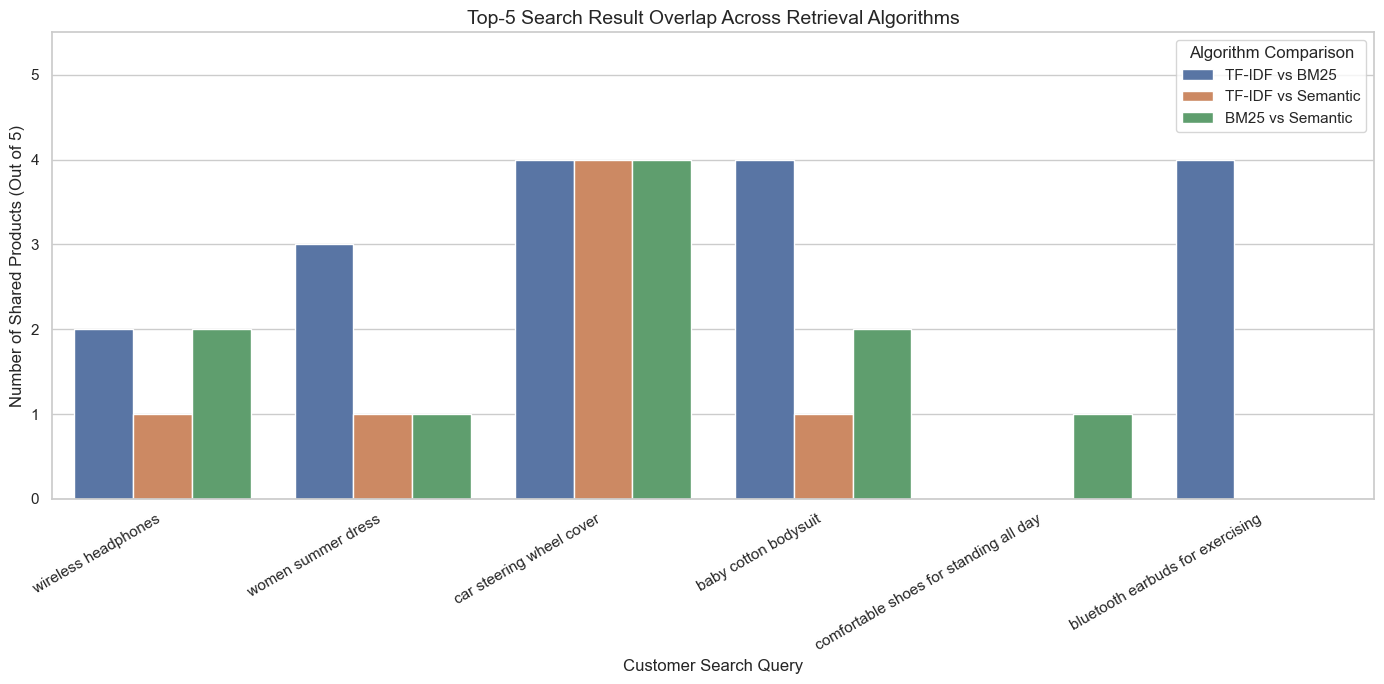

AVERAGE TOP-5 OVERLAP


,average_shared_products
algorithm_pair,
TF-IDF vs BM25,2.833333
BM25 vs Semantic,1.666667
TF-IDF vs Semantic,1.166667


In [24]:
# Reshape the comparison table for visualization
overlap_plot_df = comparison_df.melt(
    id_vars="query",
    value_vars=[
        "tfidf_bm25_overlap",
        "tfidf_semantic_overlap",
        "bm25_semantic_overlap"
    ],
    var_name="algorithm_pair",
    value_name="top_5_overlap"
)

# Create readable labels
algorithm_labels = {
    "tfidf_bm25_overlap": "TF-IDF vs BM25",
    "tfidf_semantic_overlap": "TF-IDF vs Semantic",
    "bm25_semantic_overlap": "BM25 vs Semantic"
}

overlap_plot_df["algorithm_pair"] = (
    overlap_plot_df["algorithm_pair"]
    .map(algorithm_labels)
)

# Visualize overlap across queries
plt.figure(figsize = (14, 7))

sns.barplot(
    data = overlap_plot_df,
    x = "query",
    y = "top_5_overlap",
    hue = "algorithm_pair"
)

plt.title(
    "Top-5 Search Result Overlap Across Retrieval Algorithms",
    fontsize = 14
)

plt.xlabel("Customer Search Query")
plt.ylabel("Number of Shared Products (Out of 5)")

plt.ylim(0, 5.5)

plt.xticks(rotation = 30, ha = "right")

plt.legend(
    title = "Algorithm Comparison",
    loc = "upper right"
)

plt.tight_layout()
plt.show()

# Calculate average overlap for each algorithm pair
average_overlap = (
    overlap_plot_df
    .groupby("algorithm_pair")["top_5_overlap"]
    .mean()
    .sort_values(ascending = False)
)

print("AVERAGE TOP-5 OVERLAP")
display(average_overlap.to_frame("average_shared_products"))

**How to interpret the visualization**: Each group of bars represents one customer query. The height of each bar indicates how many products two algorithms have in common. For example, a bar height of 4 means four of the five retrieved products are shared.

The average-overlap table summarizes how frequently each pair of algorithms agrees across our six test queries. **Important**: Higher average overlap doesn't necessarily mean better performance. It only indicates greater agreement between retrieval methods.

In [25]:
def compare_search_rankings(query, top_k=5):
    """
    Compare TF-IDF, BM25, and semantic search results
    side by side for a customer query.
    """

    # Retrieve ranked products from each algorithm
    tfidf = search_products_tfidf(
        query,
        top_k = top_k
    ).reset_index(drop = True)

    bm25 = search_products_bm25(
        query,
        top_k = top_k
    ).reset_index(drop = True)

    semantic = search_products_faiss(
        query,
        top_k = top_k
    ).reset_index(drop = True)

    # Create a table showing the ranked product titles
    comparison = pd.DataFrame({
        "Rank": range(1, top_k + 1),
        "TF-IDF": tfidf["title"].reindex(range(top_k)),
        "BM25": bm25["title"].reindex(range(top_k)),
        "Semantic": semantic["title"].reindex(range(top_k))
    })

    return comparison


# Examine two queries where different retrieval
# approaches may produce meaningfully different results
queries_to_inspect = [
    "women summer dress",
    "comfortable shoes for standing all day"
]

for query in queries_to_inspect:

    print("\n" + "=" * 85)
    print(f"QUERY: {query}")
    print("=" * 85)

    display(
        compare_search_rankings(
            query,
            top_k = 5
        )
    )


QUERY: women summer dress


,Rank,TF-IDF,BM25,Semantic
0,1,Summer Womens One Shouder Mini Dress Cutout Waist Beach Party Short Dress,Women Dresses Summer Pleated Mini Boho Dress Cute Sleeveless Flowy Beach Straight Tee Dress Round Neck Dress,Summer Womens One Shouder Mini Dress Cutout Waist Beach Party Short Dress
1,2,Women Dresses Summer Pleated Mini Boho Dress Cute Sleeveless Flowy Beach Straight Tee Dress Round Neck Dress,Dresses That Hide Belly Fat Beach Dresses for Women Summer Scoop Neck Cotton Casual T Shirt Sleeveless Loose,"Sundresses for Women,Womens Dresses Casual Sleeveless Colored Print Waist Drawstring Mini Dress with Pockets"
2,3,Hotouch Black Dress Summer Dress V Neck Babydoll Dress for Women 2023 Womens Dresses Puff Sleeve Casual Dresses,Summer Womens One Shouder Mini Dress Cutout Waist Beach Party Short Dress,Summer Dresses for Women 2023 Casual Cotton Linen Long Dress Crew Neck Sleeveless Baggy Sun Dresses with Pockets
3,4,Dresses That Hide Belly Fat Beach Dresses for Women Summer Scoop Neck Cotton Casual T Shirt Sleeveless Loose,Summer Dresses for Women 2023 Women Sleeveless Cotton Summer Beach Dress A Line Spaghetti Strap Sundress Boho Dresses,Summer Dresses for Women 2023 Hollow Out Sleeveless A Line Sundress Plus Size Casua Beach Dresses Cute Floral Tank D...
4,5,Women's Summer Dresses 2023 Casual Sleeveless Mini Dress Dressy Casual Loose Short Flowy Pleated Sundress,Women Plus Size Vintage Print Strappy Back Tankini Set Two Piece Bathing Suit Beachwear Womens Swim Tops with,Summer Dresses for Women 2023 Split V Neck Chiffon Elegant Mini Short Skirt Dresses Ruffle Tiered A Line Swing Dress



QUERY: comfortable shoes for standing all day


,Rank,TF-IDF,BM25,Semantic
0,1,Beach Sandals for Women Comfy Women Premium Orthopedic Sandal Open Toe Vintage Anti Slip Breathable for Summer,Women's Slip On Mule Sneakers Walking Shoes Fashion Leopard Printed Breathable Slippers Hiking Work Nurse Shoes Ligh...,HOBIBEAR Women's Walking Shoes Breathable Lightweight Slip On Sneakers for Indoor Outdoor Gym Casual Travel Running ...
1,2,MUK LUKS Men's Garret Shoes,Bacury Mens High Top Basketball Shoes Road Running Sneakers Tennis Sport Cross Trainer Shoes for Youth Big Kids,AEROTHOTIC Adjustable Velcro Strap Open Toe Comfort Slides for Women
2,3,"Ntpwenla Womens Winter Laced-Front Ankle Boots,Warm Casual Fashion Comfortable Shoes 8.5",Franco Sarto Women's Sela Slip-on Pointed Toe Mule,"LELEBEAR CNA Trop Shoes for Men, CNA Trop Men Outdoor Hiking Orthopedic Shoes, Asupwell Shoes"
3,4,"Liaoruay Summer Slingback Orthopedic Slide Sport Sandals, Flexible Washable Comfy Knit Thick Bottom Fish Mouth Sanda...",HOBIBEAR Women's Walking Shoes Breathable Lightweight Slip On Sneakers for Indoor Outdoor Gym Casual Travel Running ...,Dr. Motion Womens Breathable Compression Combo Pack Ankle & Knee High Socks with Arch Support 4 Pairs
4,5,SaraIris Women's Platform Boots Goth Boots Punk Boots Square Toe Boots Lace Up Combat Boots Black Boots for Women,Custom Slides Slippers Personalized Photo Text Slides Sandals Comfortable Bathroom Shower Slippers Casual Sandals Sh...,ILSE JACOBSEN HORNBAEK Women's Tulip 139 Flat | Slip-On | Low-Top Shoes


**What this code does**: It aligns the top-five rankings from all three algorithms so we can inspect the actual products being retrieved. We'll use these results to identify cases where semantic search finds relevant products that keyword search misses, as well as cases where keyword matching better preserves specific product requirements.

## 12. Evaluating Search Engine Performance

### 12.1 Business Objective

We've developed three different search algorithms for our 10,000-product catalog. Our next objective is to determine which approach retrieves products that best satisfy customer search intent.

For an e-commerce business, search quality is important because customers need to find relevant products efficiently. A search engine that retrieves irrelevant products may make product discovery more difficult, even if its underlying algorithm is technically sophisticated.

### 12.2 Why Isn't Search Result Overlap Enough?

In our previous analysis, we calculated how many products appeared in the top-five results of different algorithms. This helped us understand where TF-IDF, BM25, and semantic search agreed or disagreed. However, overlap doesn't tell us whether those products are relevant.

For example, two algorithms could retrieve the same five products, but all five might be inappropriate for the customer's needs. Alternatively, two algorithms could retrieve different products that are equally relevant. Therefore, we need an independent measure of relevance.

### 12.3 What Are Relevance Judgments?

A relevance judgment is an assessment of how well a particular product satisfies a particular search query. For our project, we'll manually evaluate a small collection of query-product pairs.

We'll use three relevance levels:

| Label | Meaning | Example |
|---|---|---|
| 0 | Not relevant | Compression socks for a query requesting shoes |
| 1 | Partially relevant | General-purpose wireless headphones for a query requesting workout earbuds |
| 2 | Highly relevant | Sweat-resistant Bluetooth sports earbuds for a workout-earbuds query |

These labels are based on product suitability for the query, not the algorithm's similarity score.

### 12.4 Why Use Three Relevance Levels?

Binary relevance labels classify products as either relevant or irrelevant. However, e-commerce relevance is often more nuanced.

A product may partially satisfy a customer's request without matching every characteristic. For example, wireless headphones may be somewhat relevant to a customer searching for sports earbuds, but dedicated workout earbuds may be a stronger match.

Using graded relevance labels allows us to evaluate whether algorithms place the most suitable products higher in their rankings.

### 12.5 Evaluation Limitations

Our manually labeled dataset will be relatively small. Therefore, our results will provide an initial comparison rather than a definitive estimate of production search performance.

Manual judgments can also be subjective. We'll document our labeling rules, use the same labels across all algorithms, and avoid treating similarity scores or customer ratings as relevance labels.

### Business Relevance

A structured relevance evaluation helps us move from subjective observations to measurable search-quality comparisons. It also provides a foundation for deciding whether a hybrid retrieval approach improves customer search results.

We need a collection of products to evaluate.

Rather than labeling only TF-IDF results or only semantic search results, we'll combine products retrieved by all three algorithms. This technique is called result pooling.

We'll collect the top 10 products from each algorithm for six queries, remove duplicate query-product pairs, and prepare the dataset for manual labeling.

In [26]:
# Define the customer queries used in our evaluation
evaluation_queries = [
    "wireless headphones",
    "women summer dress",
    "car steering wheel cover",
    "baby cotton bodysuit",
    "comfortable shoes for standing all day",
    "bluetooth earbuds for exercising"
]

# Number of products to retrieve from each algorithm
pool_depth = 10

# Store query-product pairs
evaluation_pool = []

for query in evaluation_queries:

    # Retrieve products from each algorithm
    retrieval_results = {
        "TF-IDF": search_products_tfidf(
            query, top_k = pool_depth
        ),
        "BM25": search_products_bm25(
            query, top_k = pool_depth
        ),
        "Semantic": search_products_faiss(
            query, top_k = pool_depth
        )
    }

    # Collect products from all retrieval methods
    for algorithm, results in retrieval_results.items():

        for rank, (_, product) in enumerate(
            results.iterrows(), start = 1
        ):

            evaluation_pool.append({
                "query": query,
                "product_id": product["product_id"],
                "title": product["title"],
                "algorithm": algorithm,
                "retrieval_rank": rank
            })

# Convert to DataFrame
evaluation_pool_df = pd.DataFrame(evaluation_pool)

# Keep one row per query-product pair
# A product can appear in multiple algorithms' results
evaluation_pool_df = (
    evaluation_pool_df
    .sort_values(["query", "retrieval_rank"])
    .drop_duplicates(
        subset = ["query", "product_id"]
    )
    .reset_index(drop = True)
)

print("EVALUATION POOL CREATED")

print("Number of queries:", len(evaluation_queries))

print(
    "Unique query-product pairs:",
    len(evaluation_pool_df)
)

print("\nProducts to label per query:")

display(
    evaluation_pool_df
    .groupby("query")
    .size()
    .to_frame("products_to_label")
)

display(evaluation_pool_df.head(10))

EVALUATION POOL CREATED
Number of queries: 6
Unique query-product pairs: 118

Products to label per query:


,products_to_label
query,
baby cotton bodysuit,17
bluetooth earbuds for exercising,19
car steering wheel cover,12
comfortable shoes for standing all day,26
wireless headphones,23
women summer dress,21


,query,product_id,title,algorithm,retrieval_rank
0,baby cotton bodysuit,4722,Metallica unisex-baby Baby Boys' Little Horseman Bodysuit,TF-IDF,1
1,baby cotton bodysuit,6551,"Gerber Baby Boys 3-piece Onesies Bodysuit, Footed Pant, and Cap Set",BM25,1
2,baby cotton bodysuit,2212,Gerber Baby 15 Piece Onesies Bodysuit Multi Pack,Semantic,1
3,baby cotton bodysuit,7895,"Viworld Newborn Baby Girl Romper, Infant Baby Girls Ruffle Sleeve Bodysuit Casual Toddler Coming Home Summer Jumpsui...",BM25,2
4,baby cotton bodysuit,4286,Creative Knitwear Infant Bodysuit - Striped and Solid - College Baby Miami Gameday Gear,Semantic,2
5,baby cotton bodysuit,4917,Gerber unisex-baby 6 Pack Long-sleeve Onesies Bodysuit,Semantic,3
6,baby cotton bodysuit,4,Grow by Gerber baby-boys 5-pack Short-sleeve Onesies Bodysuits,Semantic,4
7,baby cotton bodysuit,1112,Gerber Baby Boys' 2-Pack Long Sleeve Henley Onesies,TF-IDF,5
8,baby cotton bodysuit,8643,HonestBaby unisex-baby 10-pack Organic Cotton Short Sleeve Bodysuits,Semantic,5
9,baby cotton bodysuit,1595,Gerber Kids' 8-Pack Wiggle-Proof Jersey Crew Socks,TF-IDF,6


**Why we're doing this**: Each algorithm may retrieve different products. By combining their results, we create a broader evaluation set that includes products discovered through different retrieval approaches.

We remove duplicate query-product pairs so that the same product isn't labeled multiple times for the same query. **Important**: The pool is not a random sample of the entire catalog. It contains products selected by our current retrieval algorithms, which limits what our evaluation can tell us about products outside the pool.

### 12.6 Understanding Search Evaluation Metrics

We'll use two primary evaluation metrics: **Precision@K** and **Normalized Discounted Cumulative Gain (NDCG@K)**. These metrics answer different questions about search quality.

### Precision@K

Precision@K measures the proportion of the top K retrieved products that are relevant. For example, Precision@5 examines the five highest-ranked products. Suppose four of those five products are relevant.

Then:

**Precision@5 = 4 / 5 = 0.80, or 80%**

This means 80% of the top-five products were judged relevant.

#### How We'll Define Relevance

Our relevance labels range from 0 to 2. For Precision@5, we'll consider a product relevant if its label is either:

- 1: Partially relevant
- 2: Highly relevant

A label of 0 is considered irrelevant. This threshold must be applied consistently across all algorithms.

#### Limitation of Precision@K

Precision@K does not account for the order of relevant products. An algorithm that places its strongest matches first can receive the same Precision@5 as an algorithm that places those products lower in the list. This motivates our second metric.

### NDCG@K

NDCG@K measures ranking quality by considering both product relevance and ranking position. It rewards algorithms that place highly relevant products closer to the top.

The metric uses discounted cumulative gain (DCG), which assigns greater importance to results appearing earlier in the ranking. DCG is then normalized by the ideal ranking for that query.

The resulting NDCG score ranges from 0 to 1 when using nonnegative relevance labels. A score closer to 1 indicates that the ranking is closer to the best possible ordering under our relevance judgments.

### Example

Imagine two search engines retrieve the same five products.

**Algorithm A**

| Rank | Relevance |
|---|---|
| 1 | 2 |
| 2 | 2 |
| 3 | 1 |
| 4 | 0 |
| 5 | 0 |

**Algorithm B**

| Rank | Relevance |
|---|---|
| 1 | 0 |
| 2 | 1 |
| 3 | 0 |
| 4 | 2 |
| 5 | 2 |

Both algorithms have Precision@5 of 0.60 because each retrieves three relevant products.

However, Algorithm A should receive a higher NDCG@5 because its most relevant products appear earlier.

### Why Use Both Metrics?

Precision@5 tells us how many top-ranked products satisfy the customer's request at least partially. NDCG@5 tells us how effectively the algorithm prioritizes the strongest matches. Together, these metrics provide a more informative comparison than result overlap alone.

### Business Implications

In e-commerce, products near the top of search results often receive more attention than products appearing farther down. Therefore, the order of relevant products matters.

However, offline ranking metrics are only proxies for customer experience. A production system would eventually need online experimentation to determine whether improvements in search relevance translate into better customer outcomes.

In [27]:
# Retrieve product descriptions from our catalog
product_details = product_df[
    [
        "product_id",
        "description",
        "main_category"
    ]
].copy()

# Combine the evaluation pool with product details
labeling_df = evaluation_pool_df.merge(
    product_details,
    on = "product_id",
    how = "left",
    validate = "many_to_one"
)

# Add an empty column for manual relevance judgments
labeling_df["relevance_label"] = pd.Series(
    pd.NA,
    index = labeling_df.index,
    dtype = "Int64"
)

# Organize columns for easier review
labeling_df = labeling_df[
    [
        "query",
        "product_id",
        "title",
        "description",
        "main_category",
        "relevance_label"
    ]
]

# Save a copy for manual labeling
labeling_file = "search_relevance_labels.csv"

labeling_df.to_csv(
    labeling_file,
    index = False
)

print("RELEVANCE LABELING FILE CREATED")

print("File:", labeling_file)

print("Products requiring labels:", len(labeling_df))

print("\nRelevance scale:")
print("0 = Not relevant")
print("1 = Partially relevant")
print("2 = Highly relevant")

display(labeling_df.head(10))

RELEVANCE LABELING FILE CREATED
File: search_relevance_labels.csv
Products requiring labels: 118

Relevance scale:
0 = Not relevant
1 = Partially relevant
2 = Highly relevant


,query,product_id,title,description,main_category,relevance_label
0,baby cotton bodysuit,4722,Metallica unisex-baby Baby Boys' Little Horseman Bodysuit,White onesie featuring Metallica logo and Little Horseman graphic on front.,AMAZON FASHION,<NA>
1,baby cotton bodysuit,6551,"Gerber Baby Boys 3-piece Onesies Bodysuit, Footed Pant, and Cap Set","Dress him to impress with this baby boys' 3-Piece outfit! This set includes one long sleeve onesies bodysuit, one fo...",AMAZON FASHION,<NA>
2,baby cotton bodysuit,2212,Gerber Baby 15 Piece Onesies Bodysuit Multi Pack,Stock up on Onesies bodysuits with this 15-pack Grow with Me bundle! This bundle includes three 5-packs of bodysuits...,AMAZON FASHION,<NA>
3,baby cotton bodysuit,7895,"Viworld Newborn Baby Girl Romper, Infant Baby Girls Ruffle Sleeve Bodysuit Casual Toddler Coming Home Summer Jumpsui...","Newborn Baby Girl Romper, Infant Baby Girls Ruffle Sleeve Bodysuit Casual Toddler Coming Home Summer Jumpsuit with H...",AMAZON FASHION,<NA>
4,baby cotton bodysuit,4286,Creative Knitwear Infant Bodysuit - Striped and Solid - College Baby Miami Gameday Gear,What could possibly be more adorable than a beautiful baby? A beautiful baby in their very own officially NCAA licen...,AMAZON FASHION,<NA>
5,baby cotton bodysuit,4917,Gerber unisex-baby 6 Pack Long-sleeve Onesies Bodysuit,"Baby Onesies bodysuits are essential! These adorable, assorted Onesies bodysuits are made with a soft cotton fabric ...",AMAZON FASHION,<NA>
6,baby cotton bodysuit,4,Grow by Gerber baby-boys 5-pack Short-sleeve Onesies Bodysuits,"This 5-pack of baby boys' onesies bodysuits will make you say ""yippee!"" Made with a soft strentch cotton and spandex...",AMAZON FASHION,<NA>
7,baby cotton bodysuit,1112,Gerber Baby Boys' 2-Pack Long Sleeve Henley Onesies,Our baby clothes are designed to keep your little one feeling at their best and to bring parents peace of mind. With...,AMAZON FASHION,<NA>
8,baby cotton bodysuit,8643,HonestBaby unisex-baby 10-pack Organic Cotton Short Sleeve Bodysuits,The Honest Company was born of a simple purpose: to create safe and effective products for our families and yours. G...,AMAZON FASHION,<NA>
9,baby cotton bodysuit,1595,Gerber Kids' 8-Pack Wiggle-Proof Jersey Crew Socks,Our baby clothes are designed to keep your little one feeling at their best and to bring parents peace of mind. With...,AMAZON FASHION,<NA>


**What we're doing**: We're creating a CSV file containing the products that need to be evaluated. For each query-product pair, we'll review the title and description and assign a relevance label from 0 to 2. The resulting dataset will serve as the reference against which we evaluate all three search engines.

We can label the CSV in Excel or another spreadsheet editor, then load it back into Jupyter. Don't fill the labels using the algorithms' similarity scores or product star ratings. The labels should reflect whether the product satisfies the customer's search intent.

In [28]:
def precision_at_k(relevance_labels, k=5):
    """
    Calculate Precision@K using graded relevance labels.

    Labels 1 and 2 are treated as relevant.
    Label 0 is treated as irrelevant.
    """

    # Evaluate the first K results
    labels = np.asarray(relevance_labels[:k])

    # Convert graded labels into binary relevance
    binary_relevance = (labels >= 1).astype(int)

    # Calculate proportion of relevant results
    return binary_relevance.sum() / k


def dcg_at_k(relevance_labels, k=5):
    """
    Calculate Discounted Cumulative Gain at K.
    """

    labels = np.asarray(
        relevance_labels[:k],
        dtype=float
    )

    # Convert graded relevance into gains
    gains = (2 ** labels) - 1

    # Discount products appearing lower in rankings
    discounts = np.log2(
        np.arange(2, len(labels) + 2)
    )

    return np.sum(gains / discounts)


def ndcg_at_k(relevance_labels, k=5):
    """
    Calculate Normalized Discounted Cumulative Gain.
    """

    # Calculate the observed ranking's DCG
    actual_dcg = dcg_at_k(
        relevance_labels,
        k
    )

    # Construct the ideal ranking
    ideal_labels = sorted(
        relevance_labels,
        reverse=True
    )

    # Calculate ideal DCG
    ideal_dcg = dcg_at_k(
        ideal_labels,
        k
    )

    # Avoid division by zero
    if ideal_dcg == 0:
        return 0.0

    return actual_dcg / ideal_dcg


# Validate metric implementations using an example
example_labels = [2, 2, 1, 0, 0]

print("EXAMPLE METRIC CALCULATIONS")

print(
    "Precision@5:",
    round(precision_at_k(example_labels, 5), 4)
)

print(
    "NDCG@5:",
    round(ndcg_at_k(example_labels, 5), 4)
)

EXAMPLE METRIC CALCULATIONS
Precision@5: 0.6
NDCG@5: 1.0


## 13. Building a Reliable Search Evaluation Dataset

### 13.1 Why Do We Need Consistent Relevance Labels?

Our objective is to compare TF-IDF, BM25, and semantic search fairly. To do this, we need an independent assessment of whether each retrieved product satisfies the customer's search intent.

Without consistent labeling rules, our evaluation could become subjective. For example, one product might be considered highly relevant because it belongs to the correct category, while another similar product receives a lower label because its description is less detailed.

We want to avoid these inconsistencies.

### 13.2 Relevance Labeling Guidelines

We'll use the following scale:

| Label | Classification | Interpretation |
|---|---|---|
| 0 | Not relevant | The product does not satisfy the customer's core request. |
| 1 | Partially relevant | The product satisfies some aspects of the request but misses an important characteristic. |
| 2 | Highly relevant | The product directly satisfies the main product type and requested characteristics. |

### 13.3 Applying the Guidelines to Our Queries

**Wireless headphones**

Highly relevant products include wireless headphones and wireless earbuds. Partially relevant products might include related wireless audio accessories that do not fully satisfy the requested product type.

**Women summer dress**

Highly relevant products are women's dresses suitable for summer. Partially relevant products might include dresses with unclear seasonal suitability. Swimsuits, shorts, and unrelated clothing are not relevant.

**Car steering wheel cover**

Highly relevant products are steering wheel covers intended for cars. Products that are only loosely related to steering wheels, such as decorative steering wheel accessories, may be partially relevant.

**Baby cotton bodysuit**

Highly relevant products are baby bodysuits explicitly described as cotton. Baby bodysuits without confirmed cotton material may be partially relevant. Other baby clothing that is not a bodysuit should generally be considered irrelevant.

**Comfortable shoes for standing all day**

Highly relevant products are shoes described as supportive, cushioned, or suitable for prolonged wear. General-purpose footwear without clear comfort features may be partially relevant. Compression socks and unrelated accessories are not relevant because the customer specifically requested shoes.

**Bluetooth earbuds for exercising**

Highly relevant products are Bluetooth earbuds suitable for exercise, such as sweat-resistant sports earbuds. General Bluetooth earbuds without exercise-related features may be partially relevant. Headphones that are not earbuds may be partially relevant when they support the requested activity, but they do not satisfy the exact product type.

### 13.4 Avoiding Evaluation Bias

We must not assign relevance labels using:

- TF-IDF similarity scores
- BM25 scores
- Semantic similarity scores
- Product star ratings
- The ranking position assigned by an algorithm

These signals may be useful for other analyses, but they should not determine whether a product satisfies a customer's query. Ideally, the person labeling products should not know which algorithm retrieved each product.

### Business Relevance

Consistent relevance labels make search evaluation more trustworthy. They allow us to compare algorithms using the same definition of customer relevance and provide a stronger basis for business recommendations.

In [29]:
# Create a smaller evaluation pool using the top 5
# results from each retrieval algorithm

evaluation_depth = 5

labeling_records = []

for query in evaluation_queries:

    retrieval_results = {
        "TF-IDF": search_products_tfidf(
            query, top_k = evaluation_depth
        ),
        "BM25": search_products_bm25(
            query, top_k = evaluation_depth
        ),
        "Semantic": search_products_faiss(
            query, top_k = evaluation_depth
        )
    }

    for algorithm, results in retrieval_results.items():

        for _, product in results.iterrows():

            labeling_records.append({
                "query": query,
                "product_id": product["product_id"],
                "title": product["title"]
            })

# Create the evaluation DataFrame
small_pool_df = pd.DataFrame(labeling_records)

# Remove duplicate query-product pairs
small_pool_df = small_pool_df.drop_duplicates(
    subset = ["query", "product_id"]
).reset_index(drop = True)

# Add descriptions for manual review
small_pool_df = small_pool_df.merge(
    product_df[
        ["product_id", "description", "main_category"]
    ],
    on = "product_id",
    how = "left",
    validate = "many_to_one"
)

# Create an empty relevance label column
small_pool_df["relevance_label"] = pd.Series(
    pd.NA,
    index = small_pool_df.index,
    dtype = "Int64"
)

# Save the labeling file
small_pool_df.to_csv(
    "search_relevance_labels_top5.csv",
    index = False
)

print("TOP-5 LABELING DATASET CREATED")

print("Unique query-product pairs:", len(small_pool_df))

print("\nProducts requiring labels per query:")

display(
    small_pool_df
    .groupby("query")
    .size()
    .to_frame("products_to_label")
)

TOP-5 LABELING DATASET CREATED
Unique query-product pairs: 63

Products requiring labels per query:


,products_to_label
query,
baby cotton bodysuit,9
bluetooth earbuds for exercising,11
car steering wheel cover,7
comfortable shoes for standing all day,14
wireless headphones,11
women summer dress,11


**What this code does**: It creates a smaller labeling dataset containing the union of the top-five results from all three search algorithms. There are at most 90 query-product pairs before deduplication. The actual number should be lower where algorithms retrieve overlapping products.

This is an initial, pooled evaluation rather than a comprehensive benchmark. Because we only judge the top-five candidates, it won't establish whether relevant products elsewhere in the catalog were missed.

### 13.5 Moving From Relevance Labels to Performance Metrics

Once our query-product pairs have been labeled, we can evaluate each search algorithm. For every query, we'll retrieve the top five products and match those products against their manually assigned relevance labels. We'll then calculate Precision@5 and NDCG@5.

### Step 1: Retrieve Ranked Products

Each algorithm produces an ordered list of products for a given query.

For example:

| Rank | Product | Relevance |
|---|---|---|
| 1 | Product A | 2 |
| 2 | Product B | 1 |
| 3 | Product C | 2 |
| 4 | Product D | 0 |
| 5 | Product E | 0 |

### Step 2: Calculate Precision@5

We consider labels 1 and 2 relevant. In this example, three of the five products are relevant.

Precision@5 = 3 / 5 = 0.60

This indicates that 60% of the retrieved products are at least partially relevant.

### Step 3: Calculate NDCG@5

NDCG rewards rankings that place highly relevant products earlier. The ideal ordering would place products with relevance label 2 first, followed by label 1, then label 0. NDCG compares the actual ranking with this ideal ordering.

### Step 4: Average Across Queries

We'll calculate both metrics separately for each query and algorithm. Then we'll calculate the mean score across our six queries. This provides a summary of how each algorithm performs on our selected evaluation queries.

### Why Report Individual Queries?

An algorithm may perform well on specific product searches but struggle with conversational queries. Averaging everything into one score could hide these differences. Therefore, we'll report both:

- Performance by query
- Average performance across queries

### Important Limitations

Our results will depend on the quality of our manual labels and the representativeness of our six queries.

Also, because we're using a pooled top-five evaluation set, NDCG@5 will be normalized against the judged candidates rather than all potentially relevant products in the full catalog.

The evaluation is useful for comparing our current systems, but it should not be interpreted as a complete measurement of search relevance across the entire product catalog.

In [33]:
# Load the manually labeled evaluation dataset
labeled_df = pd.read_csv(
    "search_relevance_labels_top5.csv"
)

print("LABEL VALIDATION")

print("Total query-product pairs:", len(labeled_df))

# Check for missing labels
missing_labels = labeled_df["relevance_label"].isna().sum()

print("Missing relevance labels:", missing_labels)

# Check whether all labels are valid
valid_labels = {0, 1, 2}

observed_labels = set(
    labeled_df["relevance_label"].dropna().unique()
)

invalid_labels = observed_labels - valid_labels

print("Invalid relevance labels:", invalid_labels)

# Check for duplicate query-product pairs
duplicate_pairs = labeled_df.duplicated(
    subset = ["query", "product_id"]
).sum()

print("Duplicate query-product pairs:", duplicate_pairs)

# Display label distribution
print("\nRELEVANCE LABEL DISTRIBUTION")

display(
    labeled_df["relevance_label"]
    .value_counts(dropna = False)
    .sort_index()
)

# Stop if the evaluation dataset is incomplete
if missing_labels > 0:
    raise ValueError(
        "Some products are missing relevance labels. "
        "Complete the CSV before calculating metrics."
    )

if invalid_labels:
    raise ValueError(
        f"Invalid relevance labels found: {invalid_labels}"
    )

if duplicate_pairs > 0:
    raise ValueError(
        "Duplicate query-product pairs found."
    )

print("\nAll relevance labels validated successfully!")

LABEL VALIDATION
Total query-product pairs: 63
Missing relevance labels: 0
Invalid relevance labels: set()
Duplicate query-product pairs: 0

RELEVANCE LABEL DISTRIBUTION


relevance_label
0     2
1    17
2    44
Name: count, dtype: int64


All relevance labels validated successfully!


**What this code does**: It checks that every query-product pair has a valid relevance label and that no duplicate pairs exist. This validation is important because missing or inconsistent labels could produce misleading evaluation metrics.

In [34]:
# Create a lookup for relevance judgments
relevance_lookup = {
    (row["query"], row["product_id"]): int(
        row["relevance_label"]
    )
    for _, row in labeled_df.iterrows()
}

# Define the search algorithms
search_algorithms = {
    "TF-IDF": search_products_tfidf,
    "BM25": search_products_bm25,
    "Semantic": search_products_faiss
}

# Store evaluation results
evaluation_results = []

for query in evaluation_queries:

    for algorithm_name, search_function in (
        search_algorithms.items()
    ):

        # Retrieve the top five products
        results = search_function(
            query,
            top_k = 5
        )

        # Retrieve manually assigned relevance labels
        relevance_labels = []

        for product_id in results["product_id"]:

            key = (query, product_id)

            if key not in relevance_lookup:
                raise ValueError(
                    f"Missing relevance label for {key}"
                )

            relevance_labels.append(
                relevance_lookup[key]
            )

        # Calculate ranking-quality metrics
        precision = precision_at_k(
            relevance_labels,
            k=5
        )

        ndcg = ndcg_at_k(
            relevance_labels,
            k = 5
        )

        evaluation_results.append({
            "query": query,
            "algorithm": algorithm_name,
            "precision_at_5": precision,
            "ndcg_at_5": ndcg
        })

# Convert results into a DataFrame
metrics_df = pd.DataFrame(evaluation_results)

print("SEARCH PERFORMANCE BY QUERY")

display(
    metrics_df.sort_values(
        ["query", "algorithm"]
    )
)

# Calculate average performance across queries
average_metrics_df = (
    metrics_df
    .groupby("algorithm")[
        ["precision_at_5", "ndcg_at_5"]
    ]
    .mean()
    .sort_values(
        "ndcg_at_5",
        ascending = False
    )
)

print("\nAVERAGE SEARCH PERFORMANCE")

display(average_metrics_df.round(4))

SEARCH PERFORMANCE BY QUERY


,query,algorithm,precision_at_5,ndcg_at_5
10,baby cotton bodysuit,BM25,1.0,0.957835
11,baby cotton bodysuit,Semantic,1.0,0.939523
9,baby cotton bodysuit,TF-IDF,1.0,0.850834
16,bluetooth earbuds for exercising,BM25,1.0,0.989141
17,bluetooth earbuds for exercising,Semantic,1.0,0.802539
15,bluetooth earbuds for exercising,TF-IDF,1.0,0.980771
7,car steering wheel cover,BM25,1.0,1.000000
8,car steering wheel cover,Semantic,1.0,1.000000
6,car steering wheel cover,TF-IDF,1.0,1.000000
13,comfortable shoes for standing all day,BM25,1.0,0.935510



AVERAGE SEARCH PERFORMANCE


,precision_at_5,ndcg_at_5
algorithm,,
BM25,0.9667,0.9786
Semantic,0.9667,0.9523
TF-IDF,1.0000,0.9336


**What we'll learn**: The output will give us two views of performance. Performance by query will show whether individual algorithms perform better for certain customer search types.

Average performance will provide a summary of search relevance across our six evaluation queries. We should be careful not to claim that the highest-scoring algorithm is universally superior. Six queries provide a useful starting point, but they are not enough for a definitive production-level comparison.

## 14. Hybrid Search Using Reciprocal Rank Fusion

### 14.1 Business Objective

We've implemented and evaluated three retrieval approaches:

- TF-IDF: Keyword-based retrieval using term importance and cosine similarity.
- BM25: Keyword-based retrieval using term-frequency saturation and document-length normalization.
- Semantic Search: Embedding-based retrieval using Sentence Transformers and FAISS.

Each approach retrieves products differently. Our next objective is to investigate whether combining keyword-based and semantic retrieval can improve product relevance.

### 14.2 Why Combine BM25 and Semantic Search?

Customers express their shopping needs in different ways. Some use precise product terminology, while others describe their intended use or desired characteristics.

**BM25** is useful for identifying products containing specific search terms. For example, a customer searching for "cotton baby bodysuit" may benefit from matching those exact product attributes.

**Semantic search** can identify products with similar meanings even when their descriptions use different words. For example, a query about "comfortable shoes for standing all day" may retrieve footwear described as supportive or cushioned.

These approaches may retrieve complementary products. A hybrid system attempts to benefit from both.

### 14.3 What Is Reciprocal Rank Fusion?

Reciprocal Rank Fusion (RRF) is a technique for combining ranked lists from multiple retrieval algorithms. Instead of combining raw similarity scores, RRF uses each product's position in the rankings. For a product appearing in multiple ranked lists, its RRF score is:

**RRF Score = Sum of 1 / (k + rank)**

Where:
- **rank** is the product's position in a retrieval algorithm's results.
- **k** is a smoothing constant, commonly set to 60.
- The sum includes each retrieval algorithm that returned the product.

For example, suppose a product ranks:
- 2nd in BM25
- 3rd in semantic search

Its RRF score is: 1 / (60 + 2) + 1 / (60 + 3)

Approximately **0.0320**. Products appearing near the top of multiple lists generally receive higher combined scores.

### 14.4 Why Not Combine Raw BM25 and Semantic Scores?

BM25 scores and embedding similarity scores are calculated differently. Their numerical ranges are not directly comparable.

For example, a BM25 score of 15 does not necessarily represent stronger relevance than a semantic similarity score of 0.70. Simply adding these scores would create an arbitrary weighting between the algorithms. RRF avoids this problem by combining ranking positions rather than raw scores.

### 14.5 Our Evaluation Strategy

We'll:

1. Retrieve products using BM25 and semantic search.
2. Combine their rankings using RRF.
3. Return the top-ranked hybrid results.
4. Evaluate the hybrid system using the same relevance labels and metrics as our existing algorithms.

Importantly, we'll treat hybrid search as a hypothesis to test, not an automatic improvement.

### Business Relevance

If hybrid search improves retrieval relevance, it may help customers discover suitable products across a wider range of search behaviours. However, a production recommendation would also need to consider retrieval latency, computational cost, and online customer outcomes.

In [35]:
def search_products_hybrid(
    query,
    top_k = 5,
    candidate_k = 10,
    rrf_k = 60
):
    """
    Combine BM25 and semantic search rankings
    using Reciprocal Rank Fusion (RRF).

    Parameters
    ----------
    query : str
        Customer search query.

    top_k : int
        Number of final hybrid results to return.

    candidate_k : int
        Number of candidates retrieved per algorithm.

    rrf_k : int
        RRF smoothing constant.

    Returns
    -------
    pd.DataFrame
        Hybrid-ranked products with RRF scores.
    """

    if top_k < 1 or candidate_k < top_k:
        raise ValueError(
            "Require 1 <= top_k <= candidate_k."
        )

    if rrf_k <= 0:
        raise ValueError("rrf_k must be positive.")

    # Retrieve candidates from both search engines
    bm25_results = search_products_bm25(
        query,
        top_k = candidate_k
    )

    semantic_results = search_products_faiss(
        query,
        top_k=candidate_k
    )

    # Store each product's combined RRF score
    rrf_scores = {}

    for results in [bm25_results, semantic_results]:

        # Each result contributes according to its rank
        for rank, product_id in enumerate(
            results["product_id"],
            start = 1
        ):

            rrf_scores[product_id] = (
                rrf_scores.get(product_id, 0)
                + 1 / (rrf_k + rank)
            )

    # Rank products by their combined score
    ranked_products = sorted(
        rrf_scores.items(),
        key = lambda item: (-item[1], item[0])
    )

    # Select the top K product IDs
    top_products = ranked_products[:top_k]

    # Retrieve product information from the catalog
    product_lookup = product_df.set_index(
        "product_id",
        drop=False
    )

    hybrid_records = []

    for product_id, score in top_products:

        product = product_lookup.loc[product_id]

        hybrid_records.append({
            "product_id": product_id,
            "title": product["title"],
            "main_category": product["main_category"],
            "average_rating": product["average_rating"],
            "rating_number": product["rating_number"],
            "rrf_score": score
        })

    hybrid_df = pd.DataFrame(hybrid_records)

    hybrid_df.index = pd.Index(
        range(1, len(hybrid_df) + 1),
        name = "Rank"
    )

    return hybrid_df


# Test our hybrid search engine
hybrid_results = search_products_hybrid(
    "wireless headphones",
    top_k=5
)

display(hybrid_results)

,product_id,title,main_category,average_rating,rating_number,rrf_score
Rank,,,,,,
1,2316,"JBL Vibe Buds True Wireless Headphones - Black, Small",All Electronics,4.4,89.0,0.032266
2,3283,"YICFIS Single Open Ear Headphones Wireless Bluetooth with 16mm Large Drivers for Powerful Sound, 8H Playtime Bluetoo...",All Electronics,4.1,28.0,0.031250
3,6986,"AHOKEGE Open Ear Clip-on Earbuds Wireless Bluetooth Headphones for Android iPhone, Earbud & in-Ear Headphones, Bluet...",All Electronics,3.8,61.0,0.016393
4,4352,"SoundPEATS Wireless Earbuds with Hi-Res Audio and LDAC Codec, Capsule3 Pro Bluetooth 5.3 Earphones, 43dB Hybrid Acti...",All Electronics,4.1,25.0,0.016129
5,8804,"Cosyband Sleep Headphones Wireless Headband, Sports Wireless Earphones Music Sleeping Headphones Mask Earbuds with H...",All Electronics,3.8,9.0,0.016129


**What we're doing**: We're using BM25 and FAISS to retrieve candidate products independently, then ranking their combined results using RRF. A product appearing near the top of both lists will typically receive a stronger combined score than one appearing in only one list. The RRF score is a ranking signal, not a probability of relevance.

### 14.6 How Should We Evaluate Hybrid Search?

We've already implemented Precision@5 and NDCG@5 for our individual retrieval algorithms. We can reuse these metrics for hybrid search, but we need to consider an important evaluation limitation.

### The Relevance Pool Problem

Our manually labeled dataset was created using the top-five results from TF-IDF, BM25, and semantic search. However, our hybrid search engine combines the top ten results from BM25 and semantic search. This means hybrid search may place a product in its top five that was not included in our original labeling dataset.

Such a product has **unknown relevance**, not zero relevance. Automatically assigning it a relevance score of zero would unfairly penalize hybrid search.

### How We'll Handle This

We'll first identify whether any hybrid top-five results are missing relevance labels. If there are missing labels, we'll add those query-product pairs to a small supplemental labeling file. Only after those products have been judged can we calculate comparable performance metrics.

### What Will We Compare?

We'll evaluate four retrieval systems:

| Algorithm | Retrieval Approach |
|---|---|
| TF-IDF | Keyword matching |
| BM25 | Probabilistic keyword retrieval |
| Semantic | Dense embedding similarity |
| Hybrid | BM25 + Semantic RRF |

We'll compare their average Precision@5 and NDCG@5 across the same six queries.

### Interpreting the Results

If hybrid search achieves higher NDCG@5, this suggests that it places more highly relevant products near the top for our evaluated queries. If hybrid search performs similarly to the strongest individual algorithm, its additional complexity may not be justified. If it performs worse, we should investigate which queries are affected and whether RRF promotes less relevant products.

### Important Limitations

Our relevance judgments are based on a small query set and AI-assisted assessment of product descriptions. They should be treated as provisional proxy labels rather than independently verified human ground truth.

We also need to avoid tuning RRF parameters repeatedly against this small evaluation set and then reporting the resulting scores as unbiased test performance. Our objective is to demonstrate a sound evaluation workflow, not to overstate the reliability of the results.

In [36]:
# Store hybrid results across our evaluation queries
hybrid_evaluation_results = []

# Store query-product pairs missing relevance labels
missing_hybrid_labels = []

# Existing relevance labels from Cell 51
existing_label_keys = set(
    zip(
        labeled_df["query"],
        labeled_df["product_id"]
    )
)

for query in evaluation_queries:

    results = search_products_hybrid(
        query,
        top_k = 5,
        candidate_k = 10
    )

    for rank, (_, product) in enumerate(
        results.iterrows(),
        start = 1
    ):

        product_id = product["product_id"]

        hybrid_evaluation_results.append({
            "query": query,
            "product_id": product_id,
            "rank": rank,
            "rrf_score": product["rrf_score"]
        })

        # Identify products without relevance judgments
        if (query, product_id) not in existing_label_keys:

            missing_hybrid_labels.append({
                "query": query,
                "product_id": product_id,
                "title": product["title"]
            })

# Convert to DataFrames
hybrid_evaluation_df = pd.DataFrame(
    hybrid_evaluation_results
)

missing_hybrid_df = pd.DataFrame(
    missing_hybrid_labels,
    columns = ["query", "product_id", "title"]
).drop_duplicates(
    subset = ["query", "product_id"]
)

print("HYBRID SEARCH EVALUATION COVERAGE")

print(
    "Hybrid results:",
    len(hybrid_evaluation_df)
)

print(
    "Products missing relevance labels:",
    len(missing_hybrid_df)
)

if not missing_hybrid_df.empty:

    # Add descriptions to support relevance assessment
    missing_hybrid_df = missing_hybrid_df.merge(
        product_df[
            [
                "product_id",
                "description",
                "main_category"
            ]
        ],
        on="product_id",
        how="left",
        validate="many_to_one"
    )

    missing_hybrid_df["relevance_label"] = pd.NA

    # Save only the additional products
    missing_hybrid_df.to_csv(
        "hybrid_missing_relevance_labels.csv",
        index = False
    )

    display(missing_hybrid_df)

    print(
        "\nSupplemental labeling file created:",
        "hybrid_missing_relevance_labels.csv"
    )

else:
    print(
        "\nAll hybrid top-5 products already have labels."
    )

HYBRID SEARCH EVALUATION COVERAGE
Hybrid results: 30
Products missing relevance labels: 2


,query,product_id,title,description,main_category,relevance_label
0,baby cotton bodysuit,6953,OshKosh B'Gosh baby-girls Graphic Bodysuits,B'gosh be you bodysuit made of soft cotton jersey with fun slogan graphic and nickel-free snaps on reinforced panel.,AMAZON FASHION,<NA>
1,bluetooth earbuds for exercising,3675,"AirPod Wireless Earbuds Bluetooth in Ear Earbuds Light-Weight Wireless Headphones Built-in Microphone, with Touch Co...",♫The latest popular wireless Bluetooth touch headset in 2022♫\n▶Feature\nⒶ Unparalleled Sound Experience\nHigh-sensi...,All Electronics,<NA>



Supplemental labeling file created: hybrid_missing_relevance_labels.csv


**Why this matters**: We cannot fairly calculate NDCG@5 if some retrieved products have unknown relevance This cell checks whether our existing evaluation labels cover the hybrid results. It does not overwrite your completed relevance-labeling file.

In [38]:
# Compare all four search algorithms
query = "comfortable shoes for standing all day"

search_methods = {
    "TF-IDF": search_products_tfidf,
    "BM25": search_products_bm25,
    "Semantic": search_products_faiss,
    "Hybrid": search_products_hybrid
}

comparison = {}

for name, search_function in search_methods.items():
    results = search_function(query, top_k=5)
    comparison[name] = results["title"].tolist()

# Display the results side by side
final_comparison = pd.DataFrame(comparison)
final_comparison.index = range(1, len(final_comparison) + 1)
final_comparison.index.name = "Rank"

display(final_comparison)

,TF-IDF,BM25,Semantic,Hybrid
Rank,,,,
1,Beach Sandals for Women Comfy Women Premium Orthopedic Sandal Open Toe Vintage Anti Slip Breathable for Summer,Women's Slip On Mule Sneakers Walking Shoes Fashion Leopard Printed Breathable Slippers Hiking Work Nurse Shoes Ligh...,HOBIBEAR Women's Walking Shoes Breathable Lightweight Slip On Sneakers for Indoor Outdoor Gym Casual Travel Running ...,HOBIBEAR Women's Walking Shoes Breathable Lightweight Slip On Sneakers for Indoor Outdoor Gym Casual Travel Running ...
2,MUK LUKS Men's Garret Shoes,Bacury Mens High Top Basketball Shoes Road Running Sneakers Tennis Sport Cross Trainer Shoes for Youth Big Kids,AEROTHOTIC Adjustable Velcro Strap Open Toe Comfort Slides for Women,Women's Slip On Mule Sneakers Walking Shoes Fashion Leopard Printed Breathable Slippers Hiking Work Nurse Shoes Ligh...
3,"Ntpwenla Womens Winter Laced-Front Ankle Boots,Warm Casual Fashion Comfortable Shoes 8.5",Franco Sarto Women's Sela Slip-on Pointed Toe Mule,"LELEBEAR CNA Trop Shoes for Men, CNA Trop Men Outdoor Hiking Orthopedic Shoes, Asupwell Shoes",AEROTHOTIC Adjustable Velcro Strap Open Toe Comfort Slides for Women
4,"Liaoruay Summer Slingback Orthopedic Slide Sport Sandals, Flexible Washable Comfy Knit Thick Bottom Fish Mouth Sanda...",HOBIBEAR Women's Walking Shoes Breathable Lightweight Slip On Sneakers for Indoor Outdoor Gym Casual Travel Running ...,Dr. Motion Womens Breathable Compression Combo Pack Ankle & Knee High Socks with Arch Support 4 Pairs,Bacury Mens High Top Basketball Shoes Road Running Sneakers Tennis Sport Cross Trainer Shoes for Youth Big Kids
5,SaraIris Women's Platform Boots Goth Boots Punk Boots Square Toe Boots Lace Up Combat Boots Black Boots for Women,Custom Slides Slippers Personalized Photo Text Slides Sandals Comfortable Bathroom Shower Slippers Casual Sandals Sh...,ILSE JACOBSEN HORNBAEK Women's Tulip 139 Flat | Slip-On | Low-Top Shoes,"LELEBEAR CNA Trop Shoes for Men, CNA Trop Men Outdoor Hiking Orthopedic Shoes, Asupwell Shoes"


**What we're doing**: Comparing which products each algorithm prioritizes. This demonstrates their ranking differences, but doesn't establish which is most accurate.

## 15. Final Results and Business Insights

### Project Overview

This project developed an e-commerce search system using a catalog of 10,000 Amazon products.

We implemented four retrieval approaches:

| Algorithm | How It Works |
|---|---|
| TF-IDF | Matches products using keyword importance and cosine similarity. |
| BM25 | Ranks products using keyword relevance and document-length normalization. |
| Semantic Search | Uses Sentence Transformer embeddings and FAISS to find semantically similar products. |
| Hybrid Search | Combines BM25 and semantic rankings using Reciprocal Rank Fusion (RRF). |

### Key Findings

**1. Keyword-based retrieval**

TF-IDF and BM25 successfully retrieved products using matching search terms, although their rankings differed.

**2. Semantic search**

Semantic search demonstrated the ability to retrieve products using broader customer intent. For example, queries describing comfort or exercise could retrieve products with related characteristics, even without exact keyword matches. However, semantic search occasionally returned related products that did not satisfy the requested product type.

**3. Hybrid search**

We implemented a hybrid retrieval system combining BM25 and semantic search.

This demonstrates how keyword and semantic approaches can be integrated into a single ranking system. We have not established whether hybrid search improves relevance compared with the individual algorithms.

### Business Implications

An e-commerce retailer could use these approaches to support customers searching with specific product names, product characteristics, or conversational descriptions.

Improved search relevance could support product discovery and reduce friction in the shopping experience. However, customer engagement and conversion improvements would need to be validated through online experimentation.

### Limitations

- The project uses a sample of 10,000 products rather than the full catalog.
- Evaluation uses a small number of search queries and provisional relevance judgments.
- Hybrid search has not undergone formal relevance evaluation.
- Product ratings, availability, and pricing are not incorporated into ranking.
- Search latency and production scalability have not been benchmarked.

### Conclusion

This project demonstrates an end-to-end information retrieval workflow, from product text preprocessing and keyword indexing to semantic embeddings, FAISS similarity search, and hybrid ranking. The main takeaway is that different retrieval approaches capture different aspects of customer search intent.

A production-ready system would require broader relevance evaluation, performance testing, and online experimentation before selecting a final ranking strategy.